**INTRODUCCION ANALISIS EXPLORATORIO DE DATOS**

El 15 de Abril de 1912 el Titanic se hundio luego de chocar con un Iceberg.

Murieron 1502 de los 2224 pasajeros y tripulantes.

**Survived:** Es la **variable target** que intentamos predecir(0 or 1)

1 = Sobrevivio 0 = No Sobrevivio


**PassengerId:** Es el id del pasajero

**Pclass: (Passenger Class)** es la clase socio-economica del pasajero y corresponde a una caracteristica ordinal categorica con solo 3 valores (1, 2 or 3):

1 = Clase Alta

2 = Clase Media

3 = Clase Baja

**Name, Sex and Age:** significado obvio

**SibSp:** Hermanos y esposa

**Parch:** Padres e hijos

**Ticket:** Numero de ticket del pasajero

**Fare:** Tarifa del pasaje

**Cabin:** numero de cabina del pasajero

**Embarked:** puerto de embarque es una caracteristica categorica con 3 unicos valores (C, Q or S):

C = Cherbourg Q = Queenstown S = Southampton

In [1]:
!pip install pandas numpy seaborn matplotlib scikit-learn jinja2


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install pandas numpy seaborn matplotlib scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np

import seaborn as sns
sns.set_style('darkgrid')
import matplotlib
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import StratifiedKFold

import string
import warnings
warnings.filterwarnings('ignore')
SEED = 42

In [4]:
# from google.colab import drive
# drive.mount('/content/drive')

In [5]:
def concat_df(train_data, test_data):
    # Retorna un dataframe concatenado con los conjuntos de entrenamiento y prueba
    return pd.concat([train_data, test_data], sort=True).reset_index(drop=True)

def divide_df(all_data):
    # Retorna dfs divididos de los conjuntos de entrenamiento y prueba
    return all_data.loc[:890], all_data.loc[891:].drop(['Survived'], axis=1)

df_train = pd.read_csv('titanic_train.csv')
df_test = pd.read_csv('titanic_test.csv')
df_all = concat_df(df_train, df_test)

df_train.name = 'Conjunto de entrenamiento'
df_test.name = 'Conjunto de prueba'
df_all.name = 'Conjunto Total'

dfs = [df_train, df_test]
#print(df_test.shape)

print('Numero de samples de entrenamiento = {}'.format(df_train.shape[0]))
print('Numero de features de entrenamiento = {}'.format(df_train.shape[1] - 1))
print('Numero de samples de prueba = {}\n'.format(df_test.shape[0]))
print('Entrenamiento X Shape = {}'.format(df_train.shape))
print('Entrenamiento y Shape = {}\n'.format(df_train['Survived'].shape[0]))
print('Prueba X Shape = {}'.format(df_test.shape))
print('Prueba y Shape = {}\n'.format(df_test.shape[0]))
print(df_train.columns)
print(df_test.columns)

Numero de samples de entrenamiento = 891
Numero de features de entrenamiento = 11
Numero de samples de prueba = 418

Entrenamiento X Shape = (891, 12)
Entrenamiento y Shape = 891

Prueba X Shape = (418, 11)
Prueba y Shape = 418

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')
Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')


In [6]:
df_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [7]:
df_test

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [8]:
df_all

,Age,Cabin,Embarked,Fare,Name,Parch,PassengerId,Pclass,Sex,SibSp,Survived,Ticket
0,22.0,NaN,S,7.2500,"Braund, Mr. Owen Harris",0,1,3,male,1,0.0,A/5 21171
1,38.0,C85,C,71.2833,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,2,1,female,1,1.0,PC 17599
2,26.0,NaN,S,7.9250,"Heikkinen, Miss. Laina",0,3,3,female,0,1.0,STON/O2. 3101282
3,35.0,C123,S,53.1000,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,4,1,female,1,1.0,113803
4,35.0,NaN,S,8.0500,"Allen, Mr. William Henry",0,5,3,male,0,0.0,373450
...,...,...,...,...,...,...,...,...,...,...,...,...
1304,NaN,NaN,S,8.0500,"Spector, Mr. Woolf",0,1305,3,male,0,NaN,A.5. 3236
1305,39.0,C105,C,108.9000,"Oliva y Ocana, Dona. Fermina",0,1306,1,female,0,NaN,PC 17758
1306,38.5,NaN,S,7.2500,"Saether, Mr. Simon Sivertsen",0,1307,3,male,0,NaN,SOTON/O.Q. 3101262
1307,NaN,NaN,S,8.0500,"Ware, Mr. Frederick",0,1308,3,male,0,NaN,359309


**¿Cual es nuestro target?**

Quienes sobrevivieron y cual fue la razon de que sobrevivan. Como influyeron las diversas variables para la supervivencia de una persona.

In [9]:
df_train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
# Verifica que la variable objetivo exista en el DataFrame (en este caso, 'Survived')
if 'Survived' in df_train.columns:

    # Selecciona únicamente las columnas numéricas (int, float, etc.)
    # Esto evita errores al intentar calcular medias sobre texto/categorías.
    numeric_columns = df_train.select_dtypes(include='number').columns

    # Confirma que exista al menos una columna numérica adicional aparte de 'Survived'
    # (La media por grupo solo tiene sentido si hay variables numéricas para comparar.)
    if len(numeric_columns) > 1:

        # Agrupa por 'Survived' (0/1) y calcula la media de cada columna numérica por grupo
        # El resultado permite comparar promedios de features entre sobrevivientes y no sobrevivientes.
        group_means = df_train.groupby(['Survived'])[numeric_columns].mean()

        # Muestra la tabla de medias por grupo
        print(group_means)

    else:
        # Si no hay suficientes columnas numéricas, no se puede hacer un análisis de medias útil
        print("No hay suficientes columnas numéricas para calcular la media.")

else:
    # Si no existe la columna objetivo, el cálculo no se puede realizar
    print("La columna 'Survived' no se encuentra en el DataFrame.")


          PassengerId  Survived    Pclass        Age     SibSp     Parch  \
Survived                                                                   
0          447.016393       0.0  2.531876  30.626179  0.553734  0.329690   
1          444.368421       1.0  1.950292  28.343690  0.473684  0.464912   

               Fare  
Survived             
0         22.117887  
1         48.395408  


In [11]:
# 1. Seleccionamos las columnas numéricas
numeric_columns = df_train.select_dtypes(include='number').columns.tolist()

# 2. Eliminamos 'Survived' de la lista para evitar el KeyError
if 'Survived' in numeric_columns:
    numeric_columns.remove('Survived')

# 3. Calculamos el promedio correctamente
df_train.groupby(['Survived'])[numeric_columns].mean()

,PassengerId,Pclass,Age,SibSp,Parch,Fare
Survived,,,,,,
0,447.016393,2.531876,30.626179,0.553734,0.329690,22.117887
1,444.368421,1.950292,28.343690,0.473684,0.464912,48.395408


In [12]:
df_train.groupby(['Survived']).count() # 0->No sobrevivieron 1->Sobrevivieron

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Survived,,,,,,,,,,,
0,549,549,549,549,424,549,549,549,549,68,549
1,342,342,342,342,290,342,342,342,342,136,340


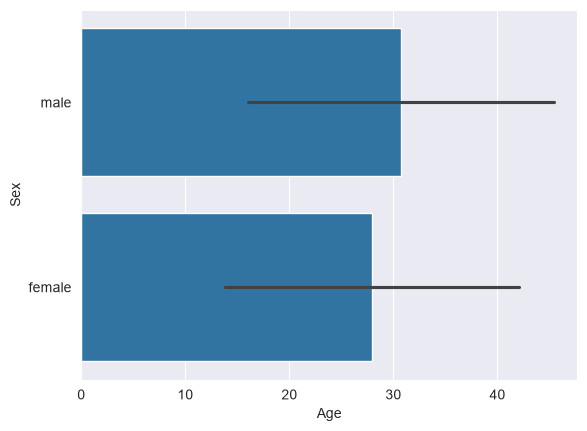

In [13]:
# Crea un gráfico de barras (barplot) para resumir la variable numérica 'Age' por cada categoría de 'Sex'.
# En Seaborn, barplot calcula por defecto el PROMEDIO (mean) de x para cada categoría de y.
sns.barplot(
    x=df_train['Age'],   # Variable numérica: se resume (promedio) dentro de cada categoría
    y=df_train['Sex'],   # Variable categórica: define los grupos (female, male, etc.)
    ci='sd'              # En vez de intervalo de confianza, muestra la DESVIACIÓN ESTÁNDAR como barra de error
                         # (si fuera None, no se dibujarían barras de error; si fuera un número como 95, sería IC 95%)
)

# Renderiza y muestra el gráfico en pantalla
plt.show()


Ese barplot está resumiendo la variable Age por cada categoría de Sex.

Eje Y (Sex): las dos categorías: female y male

Eje X (Age): edad (numérica)

Cada barra: representa el promedio de Age para ese sexo (porque sns.barplot usa por defecto estimator=mean).

La línea negra sobre cada barra (error bar): como pusiste ci='sd', esa línea muestra la desviación estándar (SD) de la edad dentro de ese grupo (no es intervalo de confianza; es dispersión).

In [14]:
df_train.groupby(['Sex'])[numeric_columns].mean() #Sex es categorica



,PassengerId,Pclass,Age,SibSp,Parch,Fare
Sex,,,,,,
female,431.028662,2.159236,27.915709,0.694268,0.649682,44.479818
male,454.147314,2.389948,30.726645,0.429809,0.235702,25.523893


In [15]:
df_train.groupby(['Sex'])[numeric_columns].std()

,PassengerId,Pclass,Age,SibSp,Parch,Fare
Sex,,,,,,
female,256.846324,0.85729,14.110146,1.156520,1.022846,57.997698
male,257.486139,0.81358,14.678201,1.061811,0.612294,43.138263


Text(0, 0.5, 'Cantidad de Pasajeros')

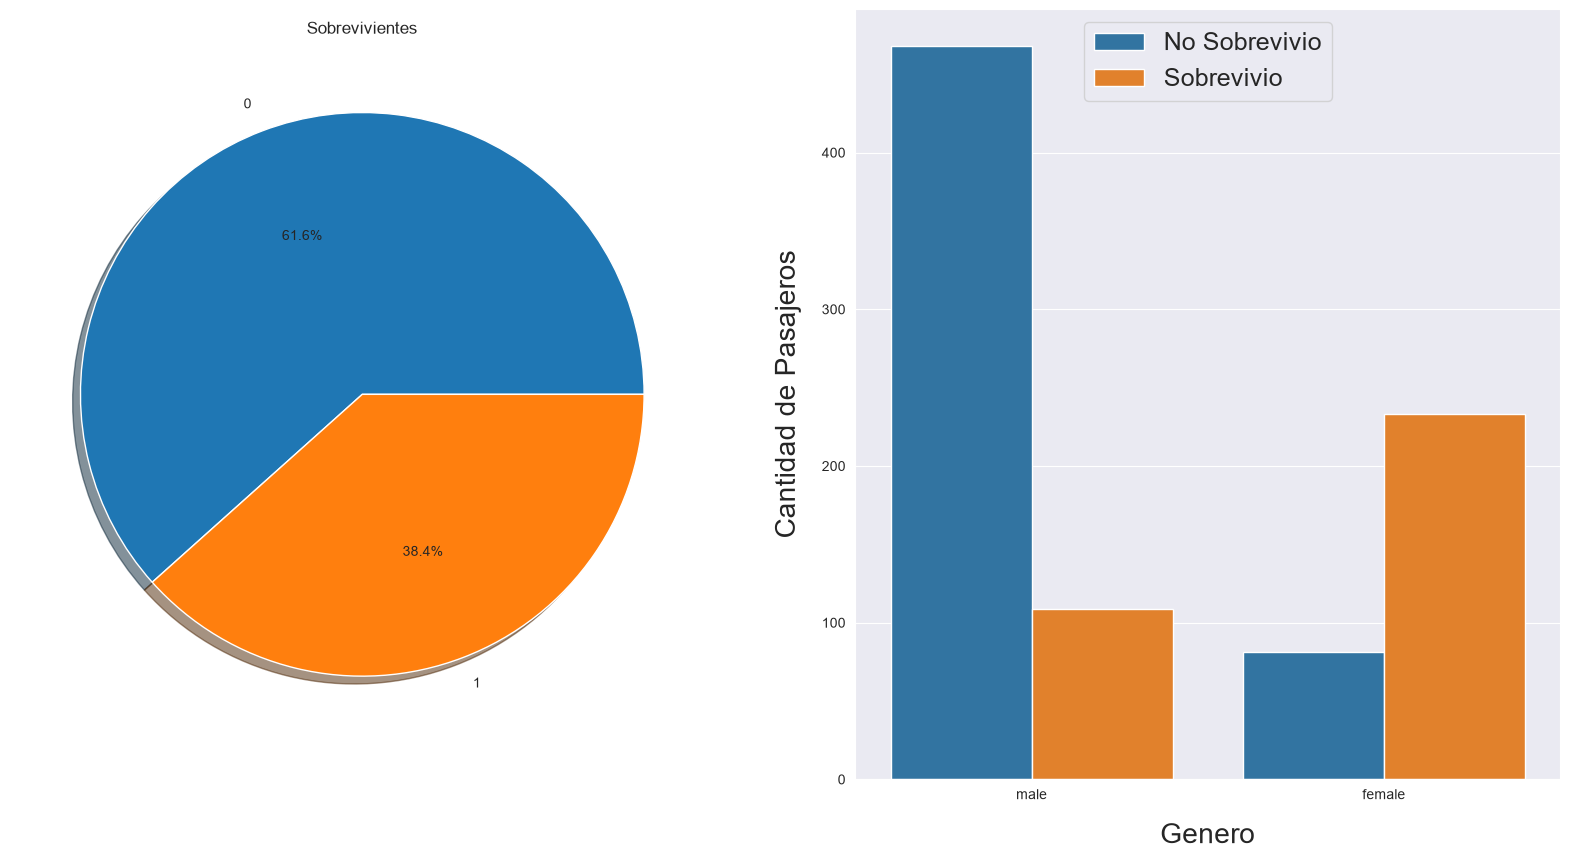

In [16]:
fig, axs = plt.subplots(1, 2, figsize = (20, 10)) #En una fila dos graficos
df_train['Survived'] .value_counts()
df_train['Survived'] .value_counts().plot.pie(autopct = '%1.1f%%', ax =axs[0], shadow = True)

axs[0].set_title('Sobrevivientes')
axs[0].set_ylabel('')

#sns.countplot('Sex', hue = 'Survived', data = df_train, ax = axs[1])
sns.countplot(x='Sex', hue='Survived', data=df_train, ax = axs[1]) #Se agrupa por Survived
plt.legend(['No Sobrevivio', 'Sobrevivio'], loc='upper center', prop={'size': 18})
plt.xlabel('Genero', size=20, labelpad=15)
plt.ylabel('Cantidad de Pasajeros', size=20, labelpad=15)


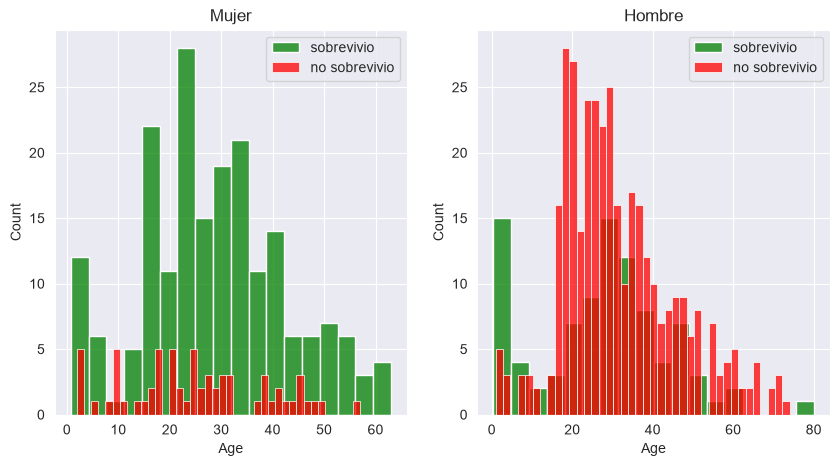

In [17]:
sobrevivio = 'sobrevivio'
no_sobrevivio = 'no sobrevivio'

fig, axes = plt.subplots(nrows=1, ncols=2, figsize = (10, 5)) #En una fila dos graficos
mujeres = df_train[df_train['Sex'] == 'female']
hombres = df_train[df_train['Sex'] == 'male']

ax = sns.histplot(mujeres[mujeres['Survived'] == 1].Age.dropna(), bins=18, label=sobrevivio, color='green', ax=axes[0], kde=False)
ax = sns.histplot(mujeres[mujeres['Survived'] == 0].Age.dropna(), bins=40, label=no_sobrevivio, color='red', ax=axes[0], kde=False)
ax.legend()
ax.set_title('Mujer')

ax = sns.histplot(hombres[hombres['Survived'] == 1].Age.dropna(), bins=18, label=sobrevivio, color='green', ax=axes[1], kde=False)
ax = sns.histplot(hombres[hombres['Survived'] == 0].Age.dropna(), bins=40, label=no_sobrevivio, color='red', ax=axes[1], kde=False)
ax.legend()
_ = ax.set_title('Hombre')


**I ANALISIS DE VARIABLES O CARACTERISTICAS (FEATURES):**

Analizemos las caracteristicas de algunas variables, identifiquemos su tipo y su impacto en la supervicencia.

Variable categorica: Sexo o Genero (Sex)

Variable ordinal: Clase (Pclass)

Variable continua: Edad (Age)


**SEX**

In [18]:
df_all['PassengerId'].count()

np.int64(1309)

In [19]:
df_train['PassengerId'].count()

np.int64(891)

In [20]:
df_test['PassengerId'].count()

np.int64(418)

In [21]:
df_train['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [22]:
df_all.groupby(['Sex', 'Survived'])['Survived'].count()

Sex     Survived
female  0.0          81
        1.0         233
male    0.0         468
        1.0         109
Name: Survived, dtype: int64

        Survived
Sex             
female  0.742038
male    0.188908


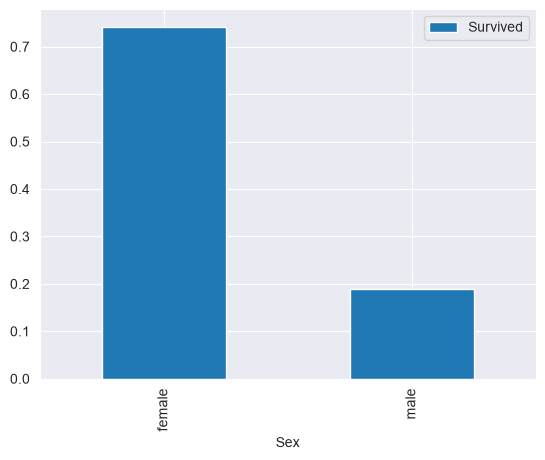

In [23]:
#Promedio de hombres y mujeres sobrevivientes
#Observemos que Sex aun la manejamos como variable categorica
print(df_all[['Sex','Survived']].groupby('Sex').mean())
df_all[['Sex','Survived']].groupby(['Sex']).mean().plot.bar()
plt.show()

**PCLASS**

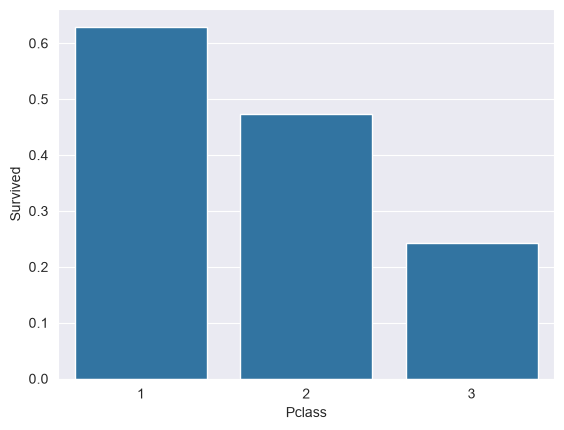

In [24]:
sns.barplot(data=df_all, x='Pclass', y='Survived', ci = None)
plt.show()

In [25]:
pd.crosstab(df_all['Pclass'],df_all['Survived'], margins=True).style.background_gradient(cmap = 'Greens')

Survived,0.000000,1.000000,All
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891


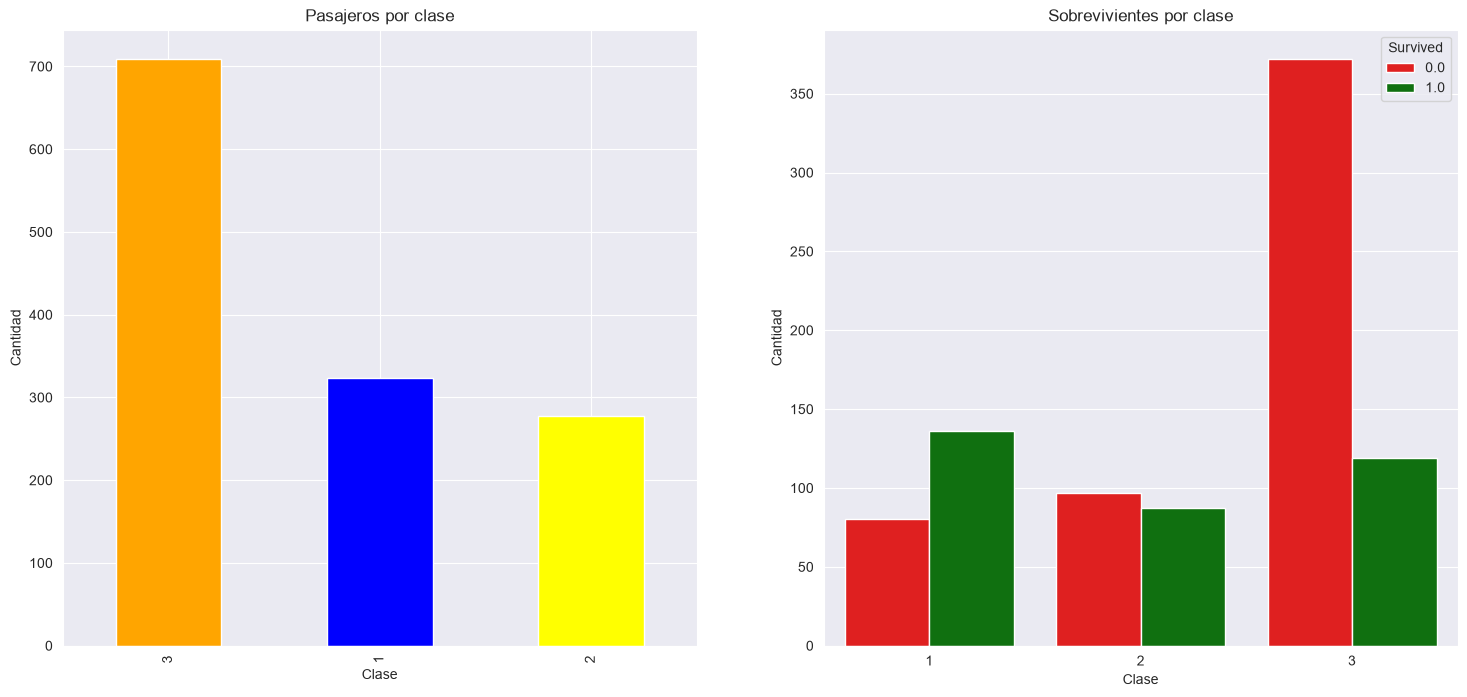

In [26]:
fig, axs = plt.subplots(1, 2, figsize = (18, 8))
df_all['Pclass'] .value_counts().plot.bar(ax =axs[0], color = ['orange', 'blue', 'yellow'])
axs[0].set_title('Pasajeros por clase')
axs[0].set_xlabel('Clase')
axs[0].set_ylabel('Cantidad')

sns.countplot(x='Pclass', hue = 'Survived', data = df_all, ax = axs[1], palette=['red',"green"])
axs[1].set_title('Sobrevivientes por clase')
axs[1].set_xlabel('Clase')
axs[1].set_ylabel('Cantidad')

plt.show()

**IMPACTO DEL SEXO Y LA CLASE:**

In [27]:
pd.crosstab([df_all['Sex'], df_all['Survived']], df_all['Pclass'], margins = True).style.background_gradient(cmap = 'summer_r')

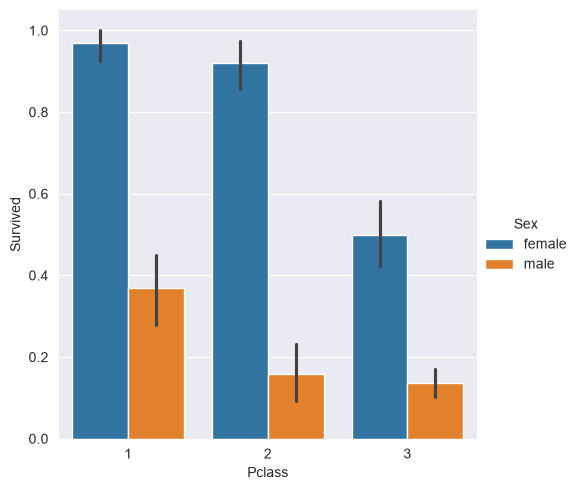

In [28]:
# Crea un gráfico categórico tipo “bar” para analizar la tasa de supervivencia por clase (Pclass),
# separando además por sexo (Sex).
sns.catplot(
    x='Pclass',          # Variable categórica (1, 2, 3): clase del pasajero
    y='Survived',        # Variable binaria (0/1): Seaborn calculará el PROMEDIO por grupo
                         # -> ese promedio se interpreta como "proporción/tasa de supervivencia"
    hue='Sex',           # Divide cada clase en barras por sexo (male/female) para comparar
    data=df_all,         # DataFrame que contiene las columnas Pclass, Survived y Sex
    kind='bar'           # Tipo de gráfico: barras con estimación agregada (por defecto mean) + barras de error
)

# Muestra el gráfico generado
plt.show()


**EDAD**

In [29]:
df_train['Age'].value_counts().to_frame().style.background_gradient(cmap = 'BuPu')

,count
Age,
24.000000,30
22.000000,27
18.000000,26
28.000000,25
19.000000,25
30.000000,25
21.000000,24
25.000000,23
36.000000,22


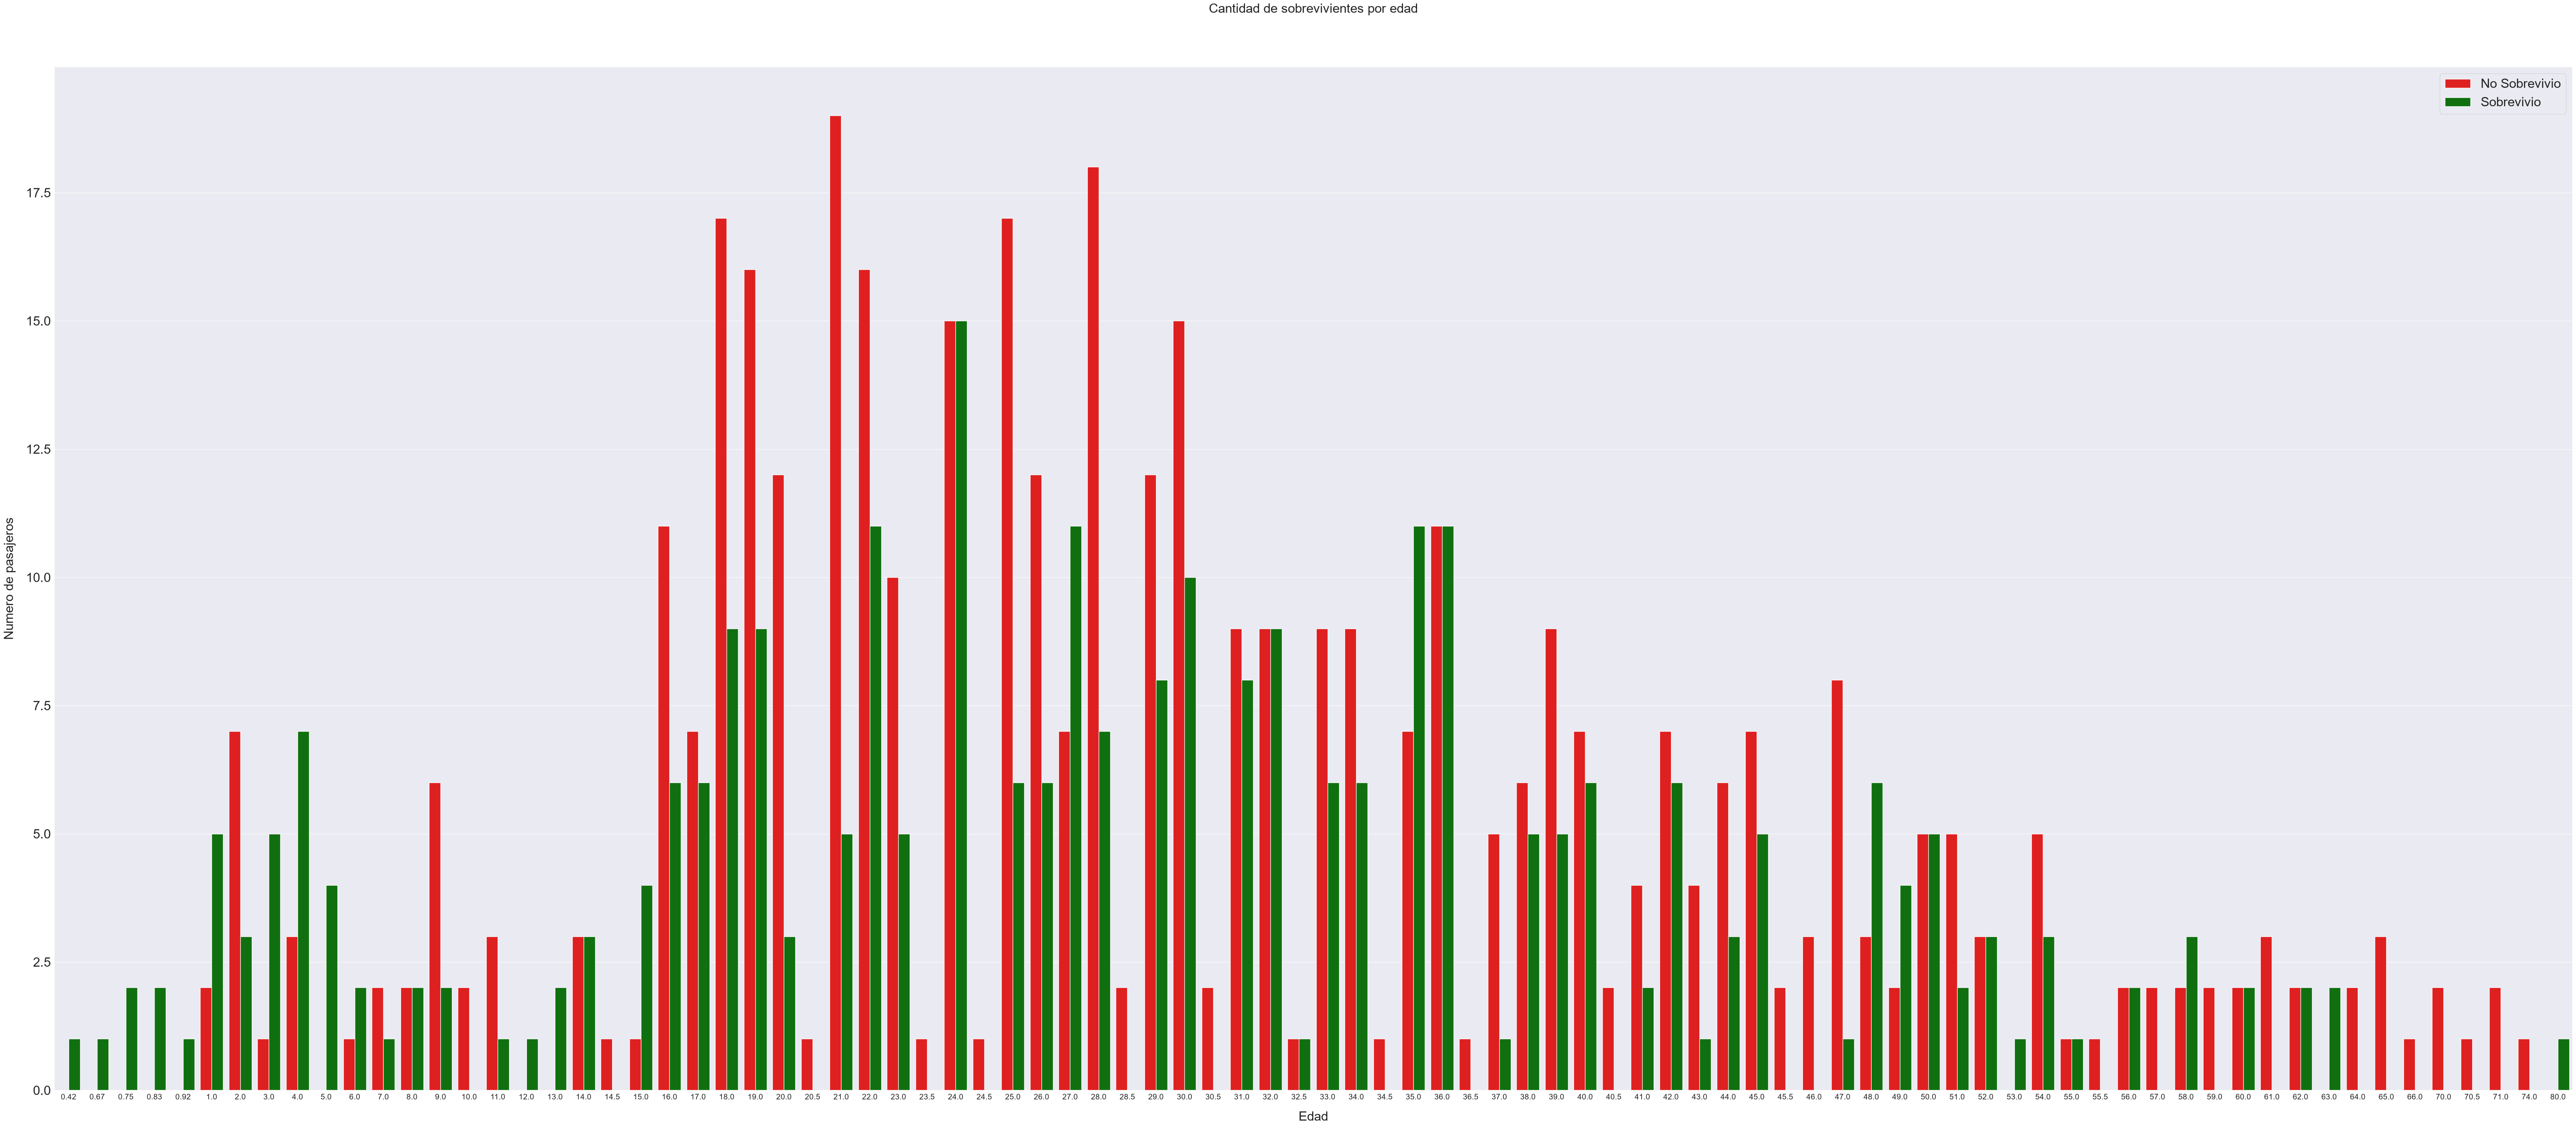

In [30]:
fig, axs = plt.subplots(figsize=(88, 36))

sns.countplot(x='Age', hue='Survived', data=df_train, palette=['red',"green"])

plt.xlabel('Edad', size=25, labelpad=20)
plt.ylabel('Numero de pasajeros', size=25, labelpad=20)
plt.tick_params(axis='x', labelsize=15)
plt.tick_params(axis='y', labelsize=25)

plt.legend(['No Sobrevivio', 'Sobrevivio'], loc='upper right', prop={'size': 25})
plt.title('Cantidad de sobrevivientes por edad', size=25, y=1.05)

plt.show()

In [31]:
#df_all.loc[df_all['Age'] <= 15, 'Age']

In [32]:
# Definimos los “cortes” (bins) de edad.
# Usamos -inf e inf para cubrir cualquier valor extremo sin tener que poner límites manuales.
# Con right=True (por defecto), los intervalos quedan así:
# (-inf, 15] , (15, 30] , (30, 45] , (45, 60] , (60, 75] , (75, inf]
bins = [-np.inf, 15, 30, 45, 60, 75, np.inf]

# Etiquetas numéricas para cada rango (equivalentes a tu age_cat 0..5)
labels = [0, 1, 2, 3, 4, 5]

# Aplicamos la misma transformación a ambos DataFrames (df_all y df_train)
for df in (df_all, df_train):

    # pd.cut “discretiza” una variable numérica (Age) en categorías según bins.
    # - labels asigna un valor a cada intervalo
    # - el resultado inicial es tipo categórico, por eso luego convertimos a entero nullable
    # - .astype("Int64") permite conservar NaN si hay edades faltantes
    df["age_cat"] = pd.cut(
        df["Age"],         # Columna numérica a discretizar
        bins=bins,         # Límites de cada categoría de edad
        labels=labels,     # Etiqueta para cada categoría
        right=True         # Incluye el límite superior (<= 15, <=30, etc.)
    ).astype("Int64")

# Vista rápida para verificar el resultado
df_all.head(10)


,Age,Cabin,Embarked,Fare,Name,Parch,PassengerId,Pclass,Sex,SibSp,Survived,Ticket,age_cat
0,22.0,NaN,S,7.2500,"Braund, Mr. Owen Harris",0,1,3,male,1,0.0,A/5 21171,1
1,38.0,C85,C,71.2833,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,2,1,female,1,1.0,PC 17599,2
2,26.0,NaN,S,7.9250,"Heikkinen, Miss. Laina",0,3,3,female,0,1.0,STON/O2. 3101282,1
3,35.0,C123,S,53.1000,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,4,1,female,1,1.0,113803,2
4,35.0,NaN,S,8.0500,"Allen, Mr. William Henry",0,5,3,male,0,0.0,373450,2
5,NaN,NaN,Q,8.4583,"Moran, Mr. James",0,6,3,male,0,0.0,330877,<NA>
6,54.0,E46,S,51.8625,"McCarthy, Mr. Timothy J",0,7,1,male,0,0.0,17463,3
7,2.0,NaN,S,21.0750,"Palsson, Master. Gosta Leonard",1,8,3,male,3,0.0,349909,0
8,27.0,NaN,S,11.1333,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",2,9,3,female,0,1.0,347742,1
9,14.0,NaN,C,30.0708,"Nasser, Mrs. Nicholas (Adele Achem)",0,10,2,female,1,1.0,237736,0


In [33]:
df_all['age_cat'].value_counts().to_frame().style.background_gradient(cmap = 'BuPu')

,count
age_cat,
1,494
2,282
3,122
0,115
4,31
5,2


In [34]:
df_train['age_cat'].value_counts().to_frame().style.background_gradient(cmap = 'BuPu')

,count
age_cat,
1,326
2,202
0,83
3,81
4,21
5,1


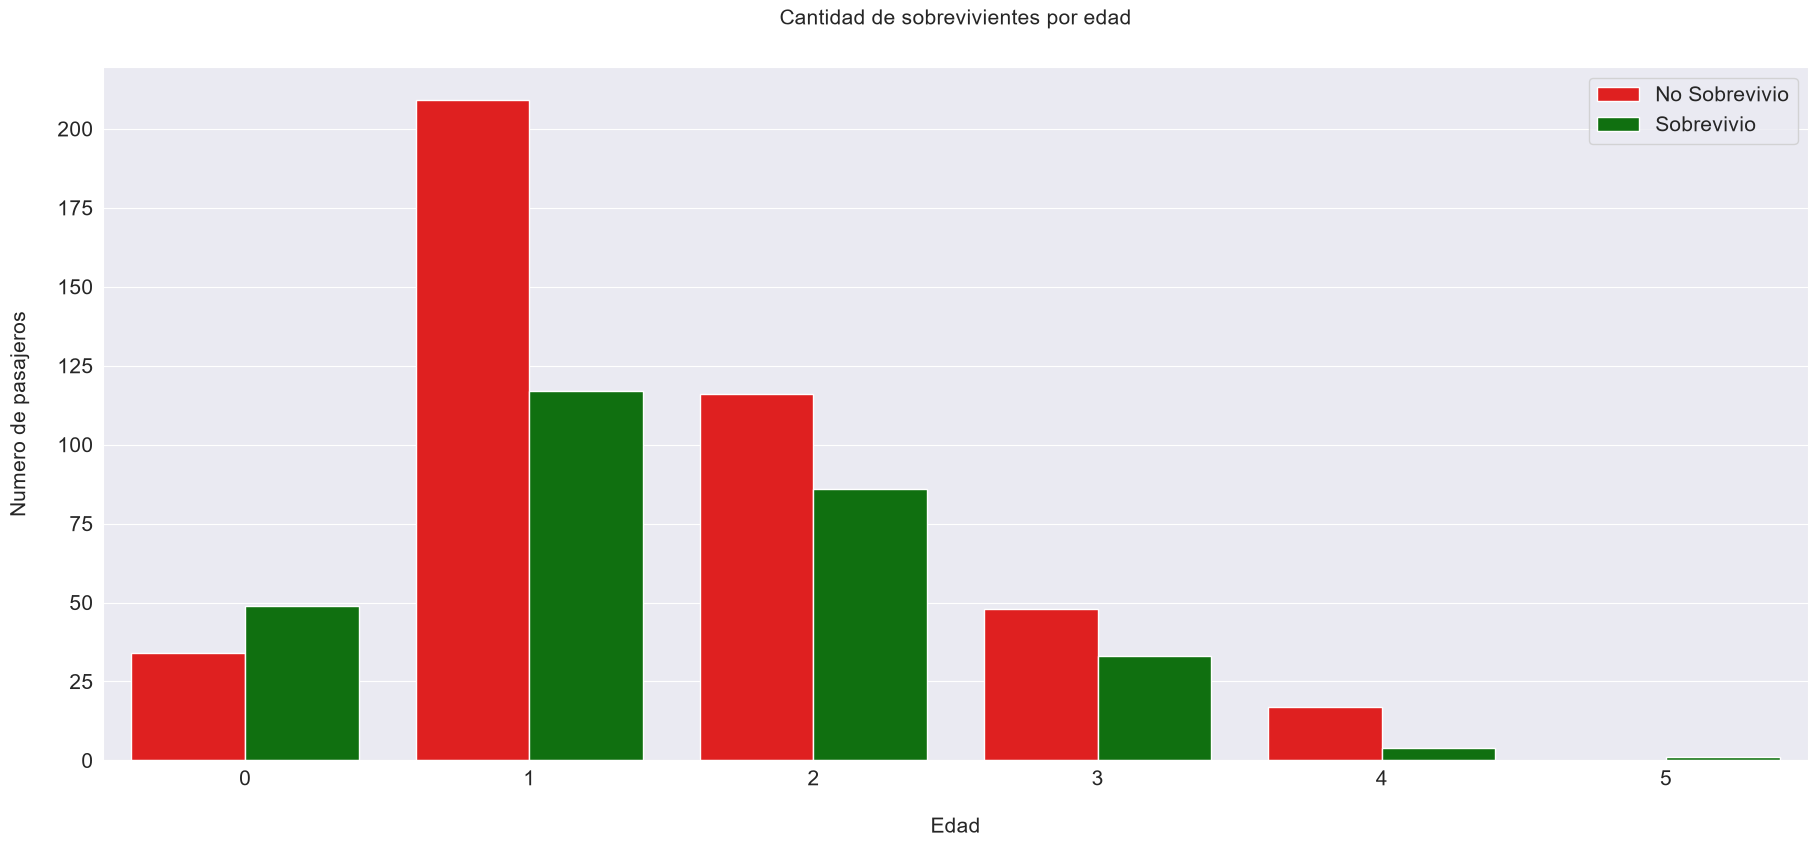

In [35]:
fig, axs = plt.subplots(figsize=(22, 9))

#sns.countplot(x='Age', hue='Survived', data=df_all, palette=['red',"green"])
sns.countplot(x='age_cat', hue='Survived', data=df_train, palette=['red',"green"])

plt.xlabel('Edad', size=15, labelpad=20)
plt.ylabel('Numero de pasajeros', size=15, labelpad=20)
plt.tick_params(axis='x', labelsize=15)
plt.tick_params(axis='y', labelsize=15)

plt.legend(['No Sobrevivio', 'Sobrevivio'], loc='upper right', prop={'size': 15})
plt.title('Cantidad de sobrevivientes por edad', size=15, y=1.05)

plt.show()

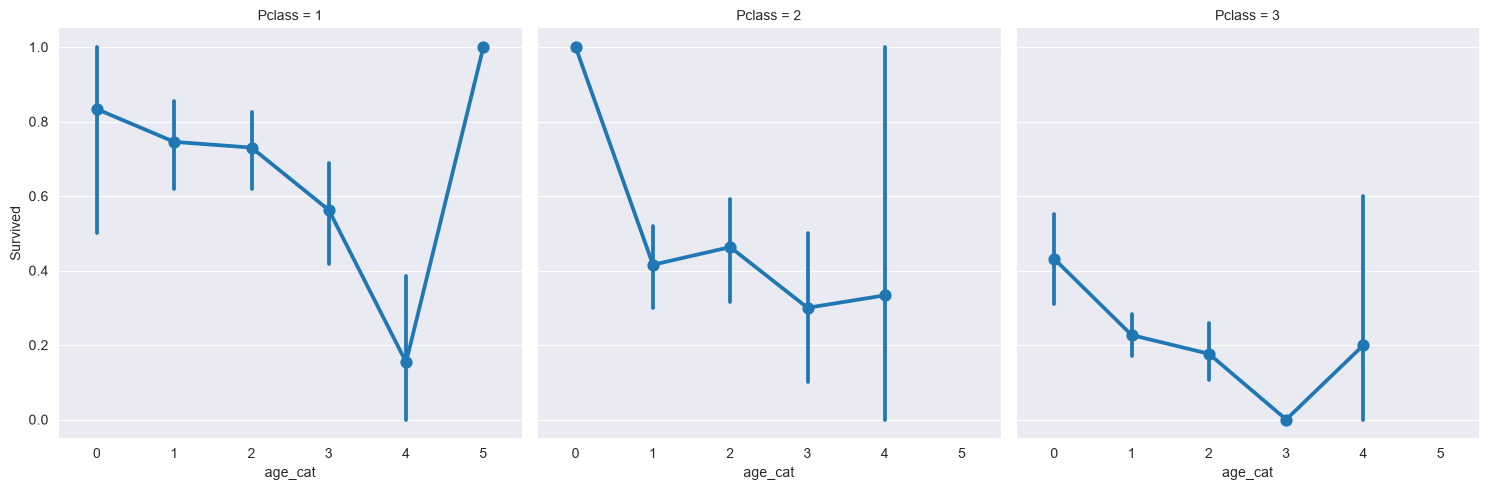

In [36]:
# Crea un gráfico categórico para analizar la supervivencia según categoría de edad (age_cat),
# separado en paneles (columnas) por clase del pasajero (Pclass).
sns.catplot(
    x='age_cat',          # Eje X: categoría de edad (0..5). Cada punto representa esa categoría.
    y='Survived',         # Eje Y: variable binaria (0/1). Seaborn calcula por defecto el PROMEDIO por grupo,
                          #       que se interpreta como "tasa/probabilidad de supervivencia".
    data=df_train,        # DataFrame con las columnas age_cat, Survived y Pclass
    col='Pclass',         # Se generan subgráficos separados para cada valor de Pclass (1, 2 y 3)
    kind='point'          # Tipo de gráfico: puntos (y líneas) mostrando el estimador (mean) por categoría
                          # + barras de error (por defecto, intervalo de confianza según versión de seaborn)
)

# Muestra el gráfico en pantalla
plt.show()


1) La clase social manda (Pclass)

Pclass = 1: supervivencia alta en casi todas las edades (sobre todo en jóvenes/adultos jóvenes).

Pclass = 2: supervivencia media.

Pclass = 3: supervivencia baja en general.

➡️ O sea, estar en 1ra clase fue una ventaja enorme.

2) Efecto de edad dentro de cada clase

Pclass = 1

age_cat 0–2 (≤15, 16–30, 31–45): supervivencia bastante alta (≈ 0.7–0.85).

age_cat 3 (46–60): baja algo (≈ ~0.55).

age_cat 4 (61–75): cae fuerte (≈ ~0.15).

age_cat 5 (>75): aparece como ~1.0 pero ojo: casi seguro es muy pocos casos.

Pclass = 2

age_cat 0 (≤15): sale ~1.0 (niños sobreviven mucho).

Luego 1–3: ronda 0.3–0.47, con tendencia general a bajar.

age_cat 4 (61–75): punto con barra enorme → muestra pequeña / incertidumbre alta.

Pclass = 3

age_cat 0: alrededor de 0.4 (niños algo mejor que adultos, pero no tan alto como en clase 1/2).

age_cat 1–2: baja a ~0.18–0.22.

age_cat 3 (46–60): cerca de 0 (muy baja supervivencia).

age_cat 4: sube algo (~0.2) pero con incertidumbre grande (pocos datos).

Sobre las barras de error (líneas verticales)

Esas líneas son la “incertidumbre” (por defecto Seaborn suele dibujar intervalos de confianza).

Barras muy largas ⇒ hay pocos pasajeros en ese grupo o mucha variabilidad, así que esa tasa no es tan confiable.

**Conclusión EDA**

Primera clase: muchas más chances de sobrevivir.

Tercera clase: muchas menos chances, especialmente adultos.

Niños tienden a sobrevivir más (se ve clarísimo en Pclass 2 y parcialmente en Pclass 3).

Los puntos “raros” (como 1.0 en >75) probablemente son por tamaño de muestra pequeño.

**Fare**

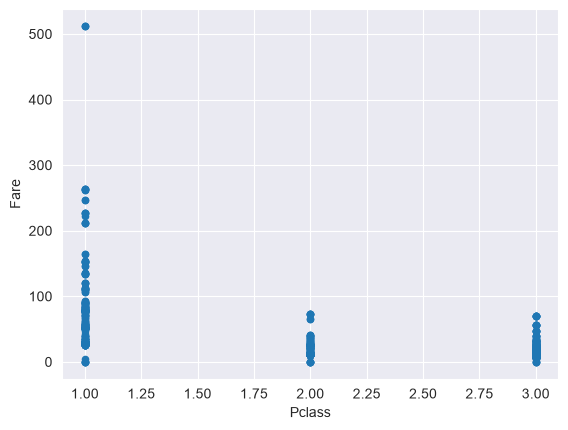

In [37]:
# diagrama de dispersión
disp= df_train.plot(kind='scatter', x='Pclass', y='Fare')

In [38]:
df_all['fare_range'] = pd.qcut(df_all['Fare'], 13)
df_all.groupby(['fare_range'])['Survived'].mean().to_frame().style.background_gradient('summer_r')


,Survived
fare_range,
"(-0.001, 7.25]",0.132530
"(7.25, 7.75]",0.315789
"(7.75, 7.896]",0.180723
"(7.896, 8.05]",0.225806
"(8.05, 10.5]",0.230769
"(10.5, 13.0]",0.461538
"(13.0, 15.742]",0.326531
"(15.742, 23.25]",0.529412
"(23.25, 26.55]",0.467532


In [39]:
# Definimos los límites (bins) EXACTOS que estás usando en tus condiciones.
# Usamos -inf e inf para cubrir cualquier valor fuera del rango sin romper el código.
# Con right=True (por defecto), los intervalos quedan tipo:
# (-inf, 7.229], (7.229, 7.75], ..., (83.158, 512.329], (512.329, inf]
bins = [-np.inf, 7.229, 7.75, 7.896, 8.05, 10.5, 13.0, 15.85, 24.0, 26.55, 33.308, 55.9, 83.158, 512.329, np.inf]

# Etiquetas 0..13 (ojo: tú llegaste hasta 12, pero con inf agregamos un bin extra al final)
labels = list(range(len(bins) - 1))

# Creamos la categoría de tarifa (fare_cat) discretizando la columna 'Fare'
# - pd.cut asigna una etiqueta según el intervalo en el que cae cada valor de Fare
# - .astype("Int64") permite mantener NaN si Fare tiene valores faltantes
df_all["fare_cat"] = pd.cut(
    df_all["Fare"],
    bins=bins,
    labels=labels,
    right=True
).astype("Int64")


#df_all.head(10)

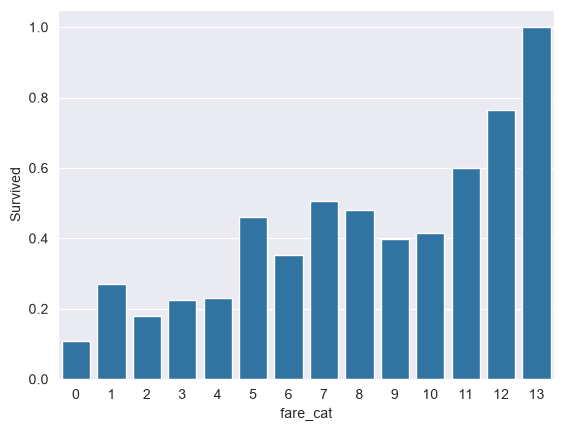

In [40]:
sns.barplot(data=df_all, x='fare_cat', y='Survived', ci = None)
plt.show()

In [41]:
tar12 = df_all.loc[df_all['fare_cat'] == 12]
tar12 = tar12[['Fare', 'fare_cat','Survived']]
print(tar12)

          Fare  fare_cat  Survived
27    263.0000        12       0.0
31    146.5208        12       1.0
62     83.4750        12       0.0
88    263.0000        12       1.0
118   247.5208        12       0.0
...        ...       ...       ...
1281   93.5000        12       NaN
1291  164.8667        12       NaN
1298  211.5000        12       NaN
1302   90.0000        12       NaN
1305  108.9000        12       NaN

[104 rows x 3 columns]


In [42]:
tar12.describe()

,Fare,fare_cat,Survived
count,104.000000,104.0,68.000000
mean,157.004686,12.0,0.764706
std,61.876426,0.0,0.427336
min,83.158300,12.0,0.000000
25%,106.425000,12.0,1.000000
50%,136.206250,12.0,1.000000
75%,211.500000,12.0,1.000000
max,263.000000,12.0,1.000000


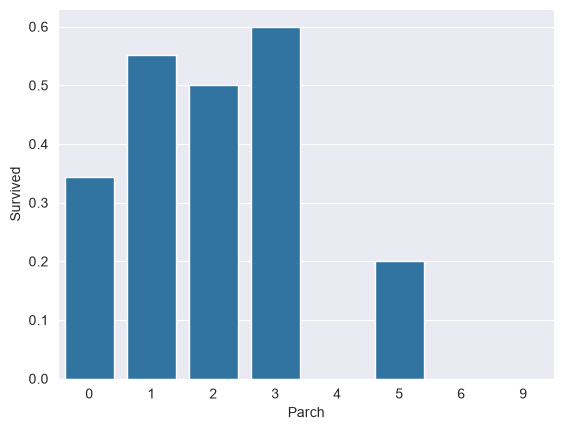

In [43]:
sns.barplot(data=df_all, x='Parch', y='Survived', ci = None)
plt.show()

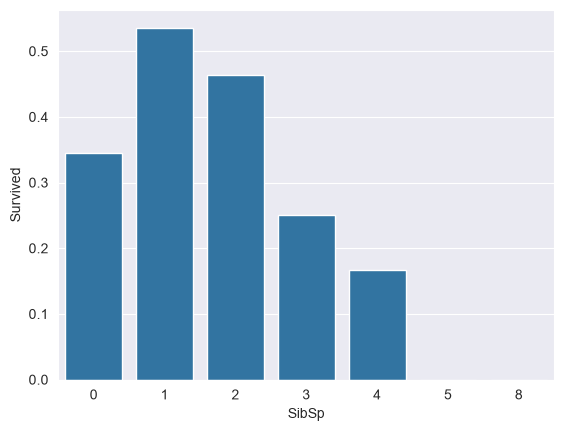

In [44]:
sns.barplot(data=df_all, x='SibSp', y='Survived', ci = None)
plt.show()

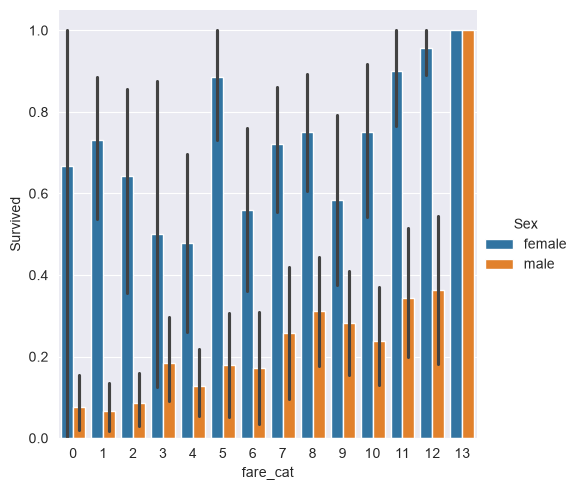

In [45]:
# Crea un gráfico categórico tipo barras para analizar la supervivencia según categoría de tarifa (fare_cat),
# comparando además hombres vs mujeres (Sex).
sns.catplot(
    x='fare_cat',        # Eje X: categoría de tarifa (bins discretos del precio del ticket)
    y='Survived',        # Eje Y: variable binaria (0/1). El promedio por grupo = tasa/proporción de supervivencia
    hue='Sex',           # Separa cada categoría de tarifa en barras por sexo para comparar (male vs female)
    data=df_all,         # DataFrame que contiene fare_cat, Survived y Sex
    kind='bar'           # Gráfico de barras con estimación agregada (por defecto mean) + barras de error
)

# Muestra el gráfico generado
plt.show()


La barra negra es un margen de error alrededor de ese promedio.

Barra negra corta → el promedio está estimado con bastante seguridad (normalmente porque hay muchos datos en ese grupo).

Barra negra larga → el promedio es más incierto (normalmente porque hay pocos pasajeros en ese grupo o los resultados varían mucho).

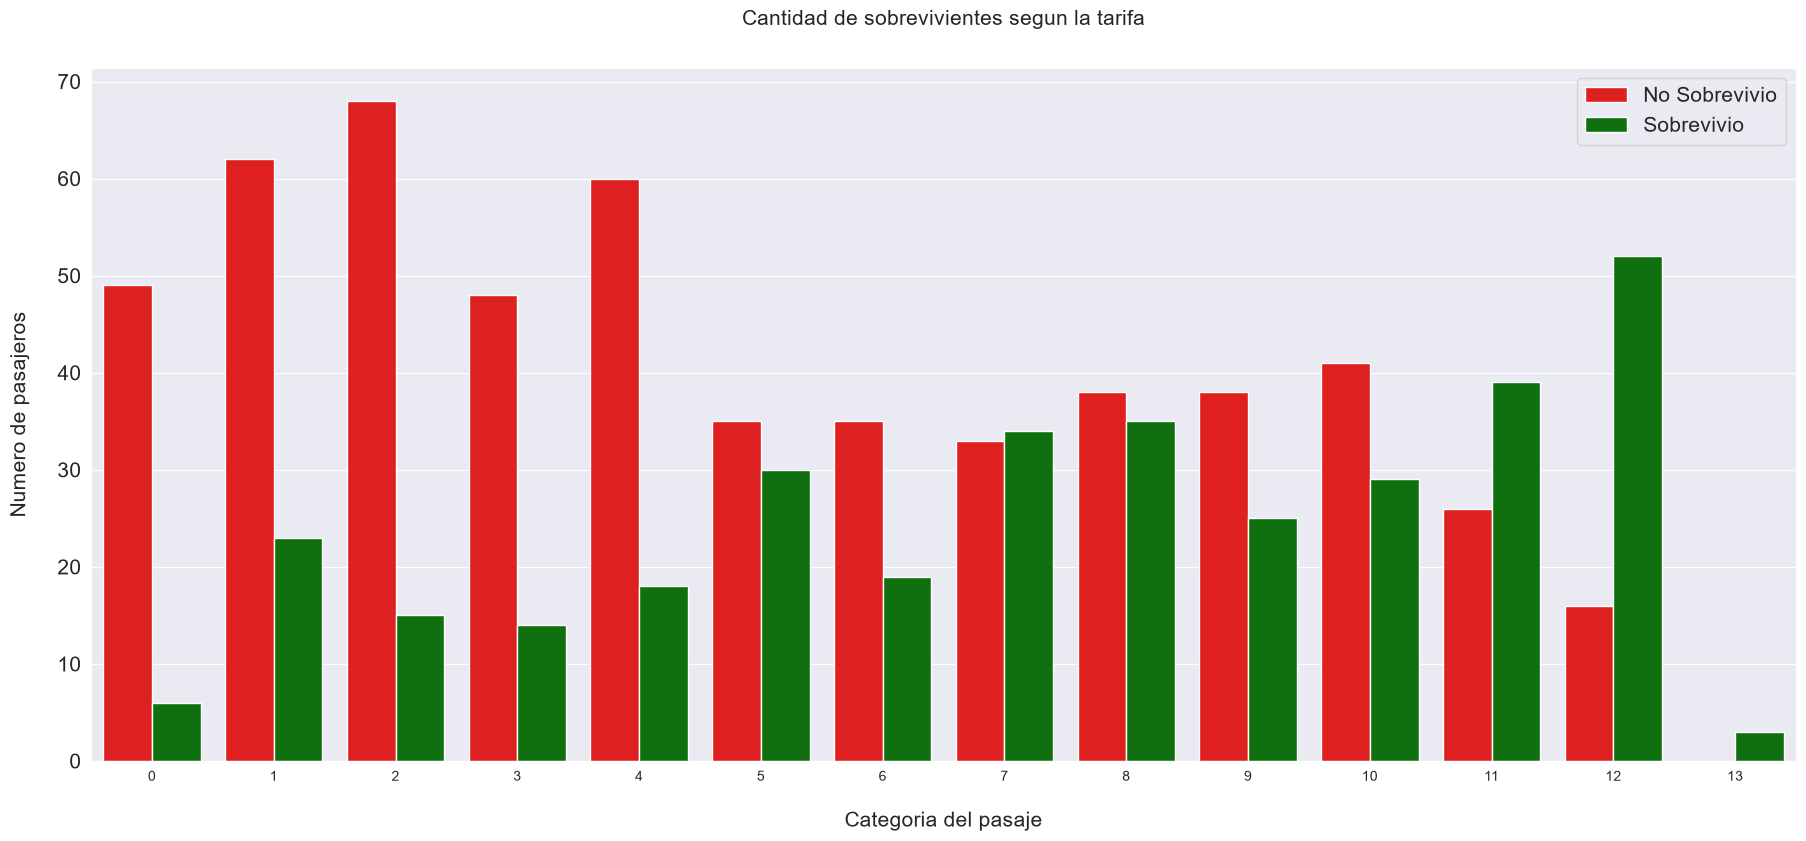

In [46]:
fig, axs = plt.subplots(figsize=(22, 9))
sns.countplot(x='fare_cat', hue='Survived', data=df_all, palette=['red',"green"])

plt.xlabel('Categoria del pasaje', size=15, labelpad=20)
plt.ylabel('Numero de pasajeros', size=15, labelpad=20)
plt.tick_params(axis='x', labelsize=10)
plt.tick_params(axis='y', labelsize=15)

plt.legend(['No Sobrevivio', 'Sobrevivio'], loc='upper right', prop={'size': 15})
plt.title('Cantidad de sobrevivientes segun la tarifa', size=15, y=1.05)

plt.show()

In [47]:
df_all.head()

,Age,Cabin,Embarked,Fare,Name,Parch,PassengerId,Pclass,Sex,SibSp,Survived,Ticket,age_cat,fare_range,fare_cat
0,22.0,NaN,S,7.2500,"Braund, Mr. Owen Harris",0,1,3,male,1,0.0,A/5 21171,1,"(-0.001, 7.25]",1
1,38.0,C85,C,71.2833,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,2,1,female,1,1.0,PC 17599,2,"(56.496, 83.475]",11
2,26.0,NaN,S,7.9250,"Heikkinen, Miss. Laina",0,3,3,female,0,1.0,STON/O2. 3101282,1,"(7.896, 8.05]",3
3,35.0,C123,S,53.1000,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,4,1,female,1,1.0,113803,2,"(34.157, 56.496]",10
4,35.0,NaN,S,8.0500,"Allen, Mr. William Henry",0,5,3,male,0,0.0,373450,2,"(7.896, 8.05]",3


**II MISSING VALUES**

Es conveniente trabajar en conjuntos de prueba y entrenamiento concatenados mientras se trabaja con valores faltantes; de lo contrario, los datos completos pueden sobreajustarse a las muestras del conjunto de prueba o entrenamiento.

In [48]:
total_datos_perdidos = df_train.isnull().sum().sort_values(ascending=False)
print(total_datos_perdidos)


Cabin          687
Age            177
age_cat        177
Embarked         2
PassengerId      0
Sex              0
Name             0
Pclass           0
Survived         0
Ticket           0
Parch            0
SibSp            0
Fare             0
dtype: int64


In [49]:
porc_perdidos = (df_train.isnull().sum()/df_train.isnull().count())*100
print(porc_perdidos)


PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
age_cat        19.865320
dtype: float64


In [50]:
round_porc_perdidos = (round(porc_perdidos, 2)).sort_values(ascending=False)
print(round_porc_perdidos)


Cabin          77.10
Age            19.87
age_cat        19.87
Embarked        0.22
PassengerId     0.00
Sex             0.00
Name            0.00
Pclass          0.00
Survived        0.00
Ticket          0.00
Parch           0.00
SibSp           0.00
Fare            0.00
dtype: float64


In [51]:
datos_perdidos = pd.concat([total_datos_perdidos, porc_perdidos], axis=1, keys=['Datos Perdidos','Porcentaje de Datos Perdidos'])
datos_perdidos.head(3)

,Datos Perdidos,Porcentaje de Datos Perdidos
Cabin,687,77.104377
Age,177,19.865320
age_cat,177,19.865320


In [52]:
df_train.isnull()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,age_cat
0,False,False,False,False,False,False,False,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,False,False,False,False,False,False,False,False,False,False,True,False,False
887,False,False,False,False,False,False,False,False,False,False,False,False,False
888,False,False,False,False,False,True,False,False,False,False,True,False,True
889,False,False,False,False,False,False,False,False,False,False,False,False,False


In [53]:
df_train.isnull().mean()  #Porque usamos mean?

PassengerId    0.000000
Survived       0.000000
Pclass         0.000000
Name           0.000000
Sex            0.000000
Age            0.198653
SibSp          0.000000
Parch          0.000000
Ticket         0.000000
Fare           0.000000
Cabin          0.771044
Embarked       0.002245
age_cat        0.198653
dtype: float64

In [54]:
#print(df_train.info())
df_train.sample(100, random_state = None)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,age_cat
81,82,1,3,"Sheerlinck, Mr. Jan Baptist",male,29.0,0,0,345779,9.5000,NaN,S,1
537,538,1,1,"LeRoy, Miss. Bertha",female,30.0,0,0,PC 17761,106.4250,NaN,C,1
666,667,0,2,"Butler, Mr. Reginald Fenton",male,25.0,0,0,234686,13.0000,NaN,S,1
77,78,0,3,"Moutal, Mr. Rahamin Haim",male,NaN,0,0,374746,8.0500,NaN,S,<NA>
513,514,1,1,"Rothschild, Mrs. Martin (Elizabeth L. Barrett)",female,54.0,1,0,PC 17603,59.4000,NaN,C,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
741,742,0,1,"Cavendish, Mr. Tyrell William",male,36.0,1,0,19877,78.8500,C46,S,2
658,659,0,2,"Eitemiller, Mr. George Floyd",male,23.0,0,0,29751,13.0000,NaN,S,1
267,268,1,3,"Persson, Mr. Ernst Ulrik",male,25.0,1,0,347083,7.7750,NaN,S,1
547,548,1,2,"Padro y Manent, Mr. Julian",male,NaN,0,0,SC/PARIS 2146,13.8625,NaN,C,<NA>


In [55]:
df_test.isnull().mean()

PassengerId    0.000000
Pclass         0.000000
Name           0.000000
Sex            0.000000
Age            0.205742
SibSp          0.000000
Parch          0.000000
Ticket         0.000000
Fare           0.002392
Cabin          0.782297
Embarked       0.000000
dtype: float64

In [56]:
#print(df_test.info())
df_test.sample(10)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
306,1198,1,"Allison, Mr. Hudson Joshua Creighton",male,30.0,1,2,113781,151.5500,C22 C26,S
115,1007,3,"Chronopoulos, Mr. Demetrios",male,18.0,1,0,2680,14.4542,NaN,C
326,1218,2,"Becker, Miss. Ruth Elizabeth",female,12.0,2,1,230136,39.0000,F4,S
25,917,3,"Robins, Mr. Alexander A",male,50.0,1,0,A/5. 3337,14.5000,NaN,S
302,1194,2,"Phillips, Mr. Escott Robert",male,43.0,0,1,S.O./P.P. 2,21.0000,NaN,S
371,1263,1,"Wilson, Miss. Helen Alice",female,31.0,0,0,16966,134.5000,E39 E41,C
139,1031,3,"Goodwin, Mr. Charles Frederick",male,40.0,1,6,CA 2144,46.9000,NaN,S
292,1184,3,"Nasr, Mr. Mustafa",male,NaN,0,0,2652,7.2292,NaN,C
153,1045,3,"Klasen, Mrs. (Hulda Kristina Eugenia Lofqvist)",female,36.0,0,2,350405,12.1833,NaN,S
19,911,3,"Assaf Khalil, Mrs. Mariana (Miriam"")""",female,45.0,0,0,2696,7.2250,NaN,C


In [57]:
def display_missing(df):
    for col in df.columns.tolist():
        print('Columna {} valores perdidos: {}'.format(col, df[col].isnull().sum()))
    print('\n')

for df in dfs:
    print('{}'.format(df.name))
    display_missing(df)

Conjunto de entrenamiento
Columna PassengerId valores perdidos: 0
Columna Survived valores perdidos: 0
Columna Pclass valores perdidos: 0
Columna Name valores perdidos: 0
Columna Sex valores perdidos: 0
Columna Age valores perdidos: 177
Columna SibSp valores perdidos: 0
Columna Parch valores perdidos: 0
Columna Ticket valores perdidos: 0
Columna Fare valores perdidos: 0
Columna Cabin valores perdidos: 687
Columna Embarked valores perdidos: 2
Columna age_cat valores perdidos: 177


Conjunto de prueba
Columna PassengerId valores perdidos: 0
Columna Pclass valores perdidos: 0
Columna Name valores perdidos: 0
Columna Sex valores perdidos: 0
Columna Age valores perdidos: 86
Columna SibSp valores perdidos: 0
Columna Parch valores perdidos: 0
Columna Ticket valores perdidos: 0
Columna Fare valores perdidos: 1
Columna Cabin valores perdidos: 327
Columna Embarked valores perdidos: 0




**AGE**

No es conveniente eliminar la edad pues debemos saber si impacto en la sobrevivencia de los pasajeros. Veremos de imputar un valor en los datos faltantes. Lo primero que se nos ocurrira es llenar las edades faltantes con la mediana de la edad de todos los datos.

In [58]:
df_all_corr = df_all[numeric_columns].corr().abs().unstack()
df_all_corr = df_all_corr.sort_values(kind="quicksort", ascending=False).reset_index()
df_all_corr.rename(columns={"level_0": "Variable 1", "level_1": "Variable 2", 0: 'Coeficiente de Correlacion'}, inplace=True)
#df_all_corr
df_all_corr[df_all_corr['Variable 1'] == 'Age']


,Variable 1,Variable 2,Coeficiente de Correlacion
2,Age,Age,1.000000
8,Age,Pclass,0.408106
12,Age,SibSp,0.243699
17,Age,Fare,0.178740
21,Age,Parch,0.150917
31,Age,PassengerId,0.028814


In [59]:
df_all_corr = df_all[numeric_columns].corr().abs().unstack()
df_all_corr = df_all_corr.sort_values(kind="quicksort", ascending=False).reset_index()
df_all_corr.rename(columns={"level_0": "Variable 1", "level_1": "Variable 2", 0: 'Coeficiente de Correlacion'}, inplace=True)
#df_all_corr
df_all_corr[df_all_corr['Variable 1'] == 'Pclass']

,Variable 1,Variable 2,Coeficiente de Correlacion
3,Pclass,Pclass,1.000000
6,Pclass,Fare,0.558629
9,Pclass,Age,0.408106
23,Pclass,SibSp,0.060832
26,Pclass,PassengerId,0.038354
33,Pclass,Parch,0.018322


In [60]:
age_by_pclass_sex = df_all.groupby(['Sex', 'Pclass'])
age_by_pclass_sex = age_by_pclass_sex[numeric_columns].median()['Age']

#print(age_by_pclass_sex)
for pclass in range(1, 4):
    for sex in ['female', 'male']:
        print('Edad Mediana de Pclass {} {}s: {}'.format(pclass, sex, age_by_pclass_sex[sex][pclass]))

print('Edad mediana de todos los pasajeros: {}'.format(df_all['Age'].median()))



Edad Mediana de Pclass 1 females: 36.0
Edad Mediana de Pclass 1 males: 42.0
Edad Mediana de Pclass 2 females: 28.0
Edad Mediana de Pclass 2 males: 29.5
Edad Mediana de Pclass 3 females: 22.0
Edad Mediana de Pclass 3 males: 25.0
Edad mediana de todos los pasajeros: 28.0


In [61]:
# Llenamos los valores perdidos de Age con la mediana del agrupamiento por Sex y Pclass .apply(lambda x: x.fillna(x.median()))
df_all['Age'] = df_all.groupby(['Sex', 'Pclass'])['Age'].transform(lambda x: x.fillna(x.median()))


In [62]:
df_all

,Age,Cabin,Embarked,Fare,Name,Parch,PassengerId,Pclass,Sex,SibSp,Survived,Ticket,age_cat,fare_range,fare_cat
0,22.0,NaN,S,7.2500,"Braund, Mr. Owen Harris",0,1,3,male,1,0.0,A/5 21171,1,"(-0.001, 7.25]",1
1,38.0,C85,C,71.2833,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,2,1,female,1,1.0,PC 17599,2,"(56.496, 83.475]",11
2,26.0,NaN,S,7.9250,"Heikkinen, Miss. Laina",0,3,3,female,0,1.0,STON/O2. 3101282,1,"(7.896, 8.05]",3
3,35.0,C123,S,53.1000,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,4,1,female,1,1.0,113803,2,"(34.157, 56.496]",10
4,35.0,NaN,S,8.0500,"Allen, Mr. William Henry",0,5,3,male,0,0.0,373450,2,"(7.896, 8.05]",3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,25.0,NaN,S,8.0500,"Spector, Mr. Woolf",0,1305,3,male,0,NaN,A.5. 3236,<NA>,"(7.896, 8.05]",3
1305,39.0,C105,C,108.9000,"Oliva y Ocana, Dona. Fermina",0,1306,1,female,0,NaN,PC 17758,2,"(83.475, 512.329]",12
1306,38.5,NaN,S,7.2500,"Saether, Mr. Simon Sivertsen",0,1307,3,male,0,NaN,SOTON/O.Q. 3101262,2,"(-0.001, 7.25]",1
1307,25.0,NaN,S,8.0500,"Ware, Mr. Frederick",0,1308,3,male,0,NaN,359309,<NA>,"(7.896, 8.05]",3


**PUERTO DE EMBARQUE**

In [63]:
df_all[df_all['Embarked'].isnull()]

,Age,Cabin,Embarked,Fare,Name,Parch,PassengerId,Pclass,Sex,SibSp,Survived,Ticket,age_cat,fare_range,fare_cat
61,38.0,B28,NaN,80.0,"Icard, Miss. Amelie",0,62,1,female,0,1.0,113572,2,"(56.496, 83.475]",11
829,62.0,B28,NaN,80.0,"Stone, Mrs. George Nelson (Martha Evelyn)",0,830,1,female,0,1.0,113572,4,"(56.496, 83.475]",11


In [64]:
df_all['Embarked'] = df_all['Embarked'].fillna('S')

**FARE**

La tarifa está relacionada con el tamaño de la familia (Parch y SibSp) y las variable Pclass. El valor de la mediana para un hombre con un boleto de tercera clase y sin familia es una opción lógica para llenar el valor faltante.

In [65]:
print('Pasaje minimo: ', df_all['Fare'].min())
print('Pasaje maximo: ', df_all['Fare'].max())

Pasaje minimo:  0.0
Pasaje maximo:  512.3292


In [66]:
df_all[df_all['Fare'].isnull()]

,Age,Cabin,Embarked,Fare,Name,Parch,PassengerId,Pclass,Sex,SibSp,Survived,Ticket,age_cat,fare_range,fare_cat
1043,60.5,NaN,S,NaN,"Storey, Mr. Thomas",0,1044,3,male,0,NaN,3701,4,NaN,<NA>


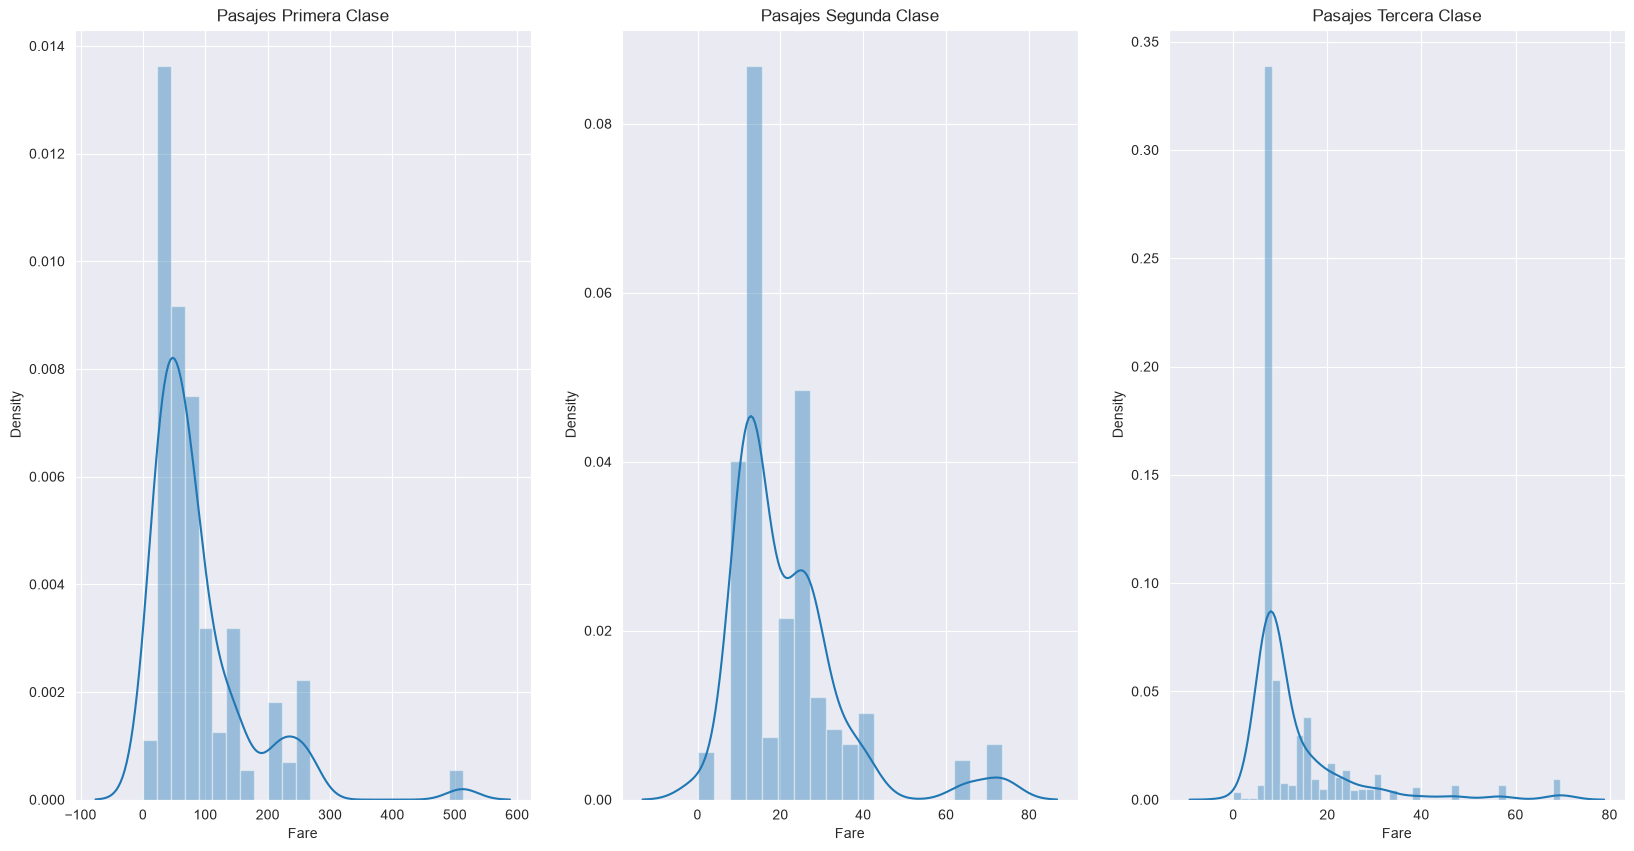

In [67]:
fig, axs = plt.subplots(1, 3, figsize = (20, 10))
sns.distplot(df_all[df_all['Pclass'] == 1]['Fare'], ax = axs[0])
axs[0].set_title('Pasajes Primera Clase')
sns.distplot(df_all[df_all['Pclass'] == 2]['Fare'], ax = axs[1])
axs[1].set_title('Pasajes Segunda Clase')
sns.distplot(df_all[df_all['Pclass'] == 3]['Fare'], ax = axs[2])
axs[2].set_title('Pasajes Tercera Clase')
plt.show()

In [68]:
med_fare = df_all.groupby(['Pclass', 'Parch', 'SibSp']).Fare.median()
print(med_fare)


Pclass  Parch  SibSp
1       0      0         31.33960
               1         75.25000
               2         51.47920
        1      0         63.35830
               1         83.15830
        2      0         83.15830
               1        120.00000
               2        262.37500
               3        263.00000
        3      1        262.37500
        4      1        263.00000
2       0      0         13.00000
               1         26.00000
               2         73.50000
               3         21.00000
        1      0         23.00000
               1         26.25000
               2         33.00000
        2      0         26.25000
               1         41.57920
        3      0         39.00000
               1         23.00000
               2         18.75000
3       0      0          7.85420
               1         14.45625
               2         19.83960
               3         16.92500
        1      0         12.47500
               1         15

In [69]:
med_fare = med_fare[3][0][0]
print(med_fare)


7.8542


In [70]:
# Llenamos el valor perdido con la mediana de la tarifa de un pasajero solo de tercera clase
df_all['Fare'] = df_all['Fare'].fillna(med_fare)
df_all['fare_cat'] = 2

df_train['Fare'] = df_train['Fare'].fillna(med_fare)
df_train['fare_cat'] = 2

df_test['Fare'] = df_test['Fare'].fillna(med_fare)
df_test['fare_cat'] = 2

In [71]:
#df_all.drop(['Age', 'Fare', 'Name', 'PassengerId', 'Ticket'], axis = 1, inplace = True)

In [72]:
df_all

,Age,Cabin,Embarked,Fare,Name,Parch,PassengerId,Pclass,Sex,SibSp,Survived,Ticket,age_cat,fare_range,fare_cat
0,22.0,NaN,S,7.2500,"Braund, Mr. Owen Harris",0,1,3,male,1,0.0,A/5 21171,1,"(-0.001, 7.25]",2
1,38.0,C85,C,71.2833,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,2,1,female,1,1.0,PC 17599,2,"(56.496, 83.475]",2
2,26.0,NaN,S,7.9250,"Heikkinen, Miss. Laina",0,3,3,female,0,1.0,STON/O2. 3101282,1,"(7.896, 8.05]",2
3,35.0,C123,S,53.1000,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,4,1,female,1,1.0,113803,2,"(34.157, 56.496]",2
4,35.0,NaN,S,8.0500,"Allen, Mr. William Henry",0,5,3,male,0,0.0,373450,2,"(7.896, 8.05]",2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,25.0,NaN,S,8.0500,"Spector, Mr. Woolf",0,1305,3,male,0,NaN,A.5. 3236,<NA>,"(7.896, 8.05]",2
1305,39.0,C105,C,108.9000,"Oliva y Ocana, Dona. Fermina",0,1306,1,female,0,NaN,PC 17758,2,"(83.475, 512.329]",2
1306,38.5,NaN,S,7.2500,"Saether, Mr. Simon Sivertsen",0,1307,3,male,0,NaN,SOTON/O.Q. 3101262,2,"(-0.001, 7.25]",2
1307,25.0,NaN,S,8.0500,"Ware, Mr. Frederick",0,1308,3,male,0,NaN,359309,<NA>,"(7.896, 8.05]",2


Sexo y Embarque se deben pasar a numerico

In [73]:
df_all['Sex'].replace(['male', 'female'], [0, 1], inplace=True)
df_all['Embarked'].replace(['S', 'C', 'Q'], [0, 1, 2], inplace=True)

0       0
1       1
2       0
3       0
4       0
       ..
1304    0
1305    1
1306    0
1307    0
1308    1
Name: Embarked, Length: 1309, dtype: object

In [74]:
df_all.head(50)

,Age,Cabin,Embarked,Fare,Name,Parch,PassengerId,Pclass,Sex,SibSp,Survived,Ticket,age_cat,fare_range,fare_cat
0,22.0,NaN,S,7.2500,"Braund, Mr. Owen Harris",0,1,3,male,1,0.0,A/5 21171,1,"(-0.001, 7.25]",2
1,38.0,C85,C,71.2833,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,2,1,female,1,1.0,PC 17599,2,"(56.496, 83.475]",2
2,26.0,NaN,S,7.9250,"Heikkinen, Miss. Laina",0,3,3,female,0,1.0,STON/O2. 3101282,1,"(7.896, 8.05]",2
3,35.0,C123,S,53.1000,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,4,1,female,1,1.0,113803,2,"(34.157, 56.496]",2
4,35.0,NaN,S,8.0500,"Allen, Mr. William Henry",0,5,3,male,0,0.0,373450,2,"(7.896, 8.05]",2
5,25.0,NaN,Q,8.4583,"Moran, Mr. James",0,6,3,male,0,0.0,330877,<NA>,"(8.05, 10.5]",2
6,54.0,E46,S,51.8625,"McCarthy, Mr. Timothy J",0,7,1,male,0,0.0,17463,3,"(34.157, 56.496]",2
7,2.0,NaN,S,21.0750,"Palsson, Master. Gosta Leonard",1,8,3,male,3,0.0,349909,0,"(15.742, 23.25]",2
8,27.0,NaN,S,11.1333,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",2,9,3,female,0,1.0,347742,1,"(10.5, 13.0]",2
9,14.0,NaN,C,30.0708,"Nasser, Mrs. Nicholas (Adele Achem)",0,10,2,female,1,1.0,237736,0,"(26.55, 34.157]",2


**Cabina**
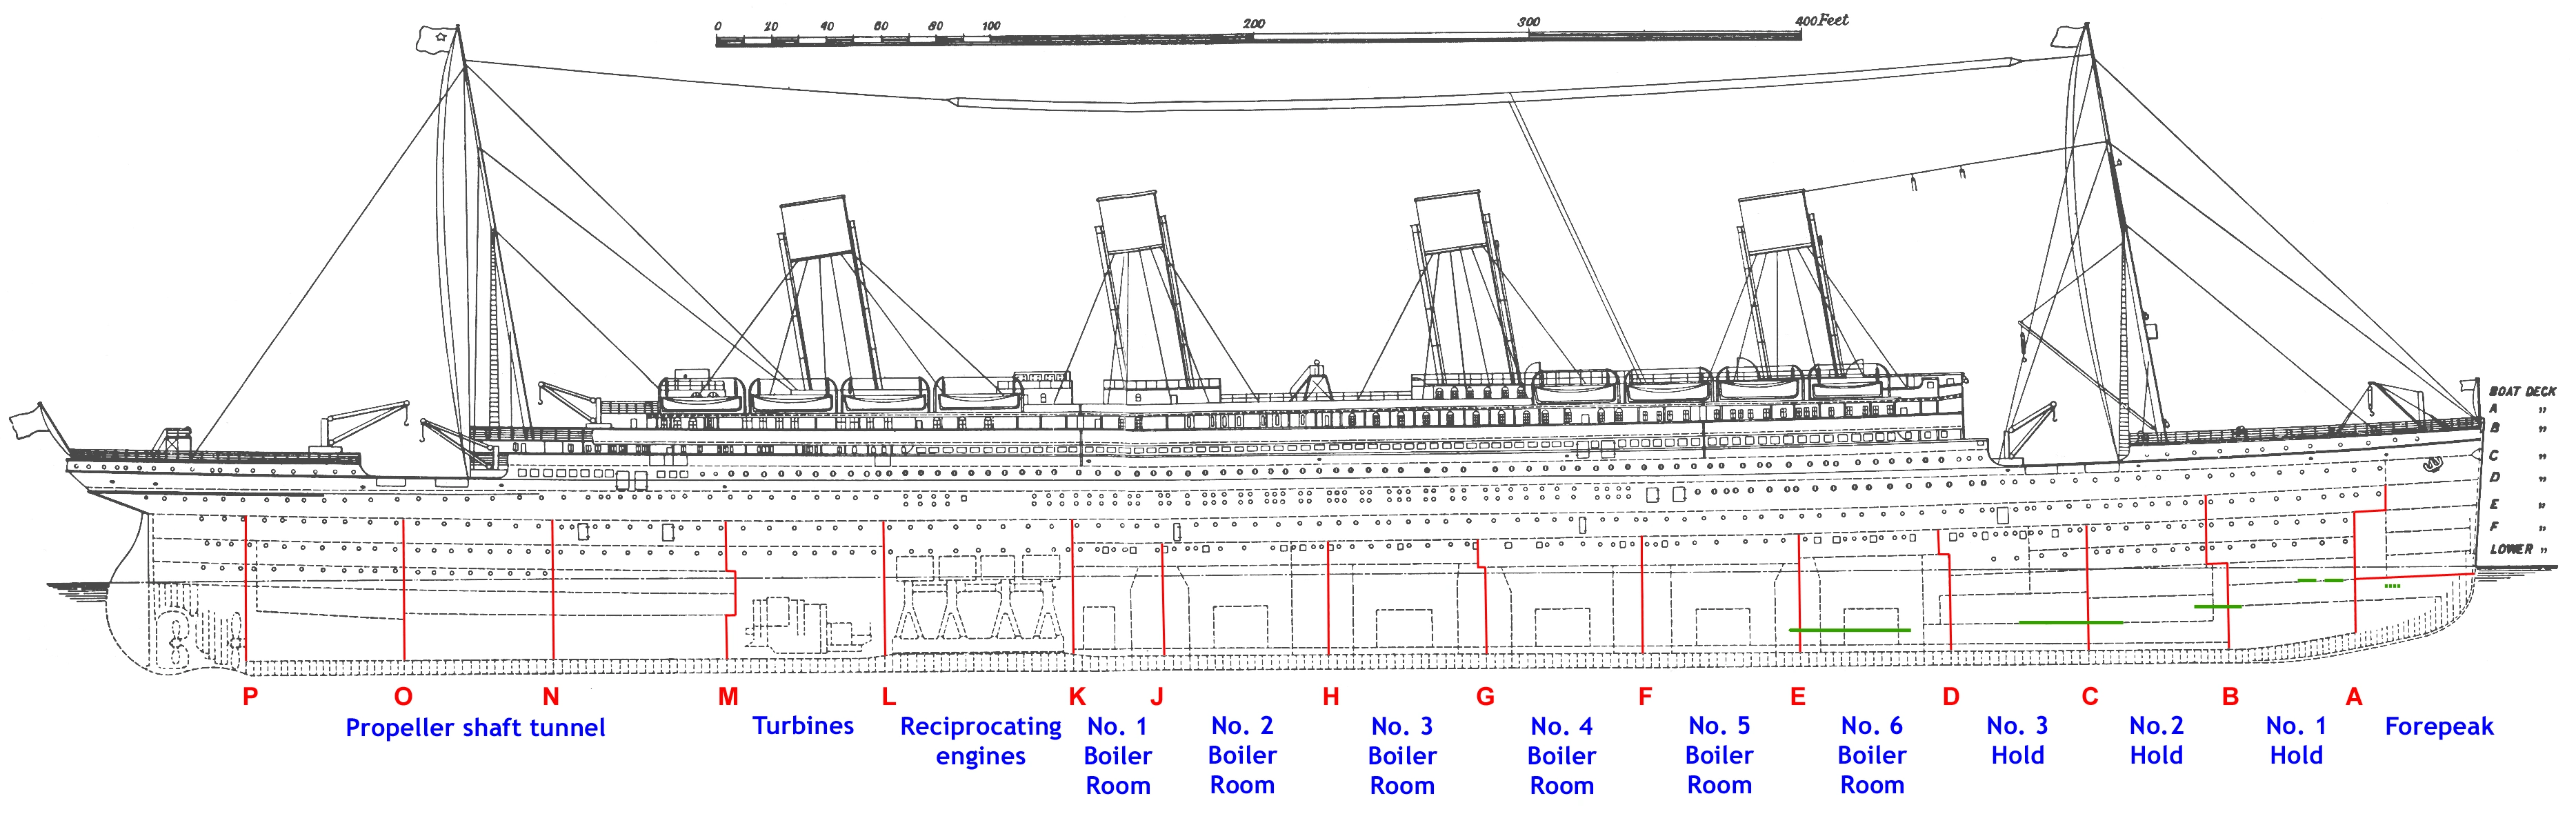

En la cubierta de botes había 6 habitaciones etiquetadas como T, U, W, X, Y, Z pero solo la cabina T está presente en el conjunto de datos.

Las cubiertas A, B y C eran solo para pasajeros de 1ra clase

Las cubiertas D y E eran para todas las clases.

Las cubiertas F y G eran para pasajeros de segunda y tercera clase.

Para ir de G a A, la distancia a la escalera aumenta, lo que podría ser un factor de supervivencia.

    0   1   2
A NaN NaN NaN
B NaN NaN NaN
C NaN NaN NaN
D NaN NaN NaN
E NaN NaN NaN
F NaN NaN NaN
G NaN NaN NaN
M NaN NaN NaN
T NaN NaN NaN


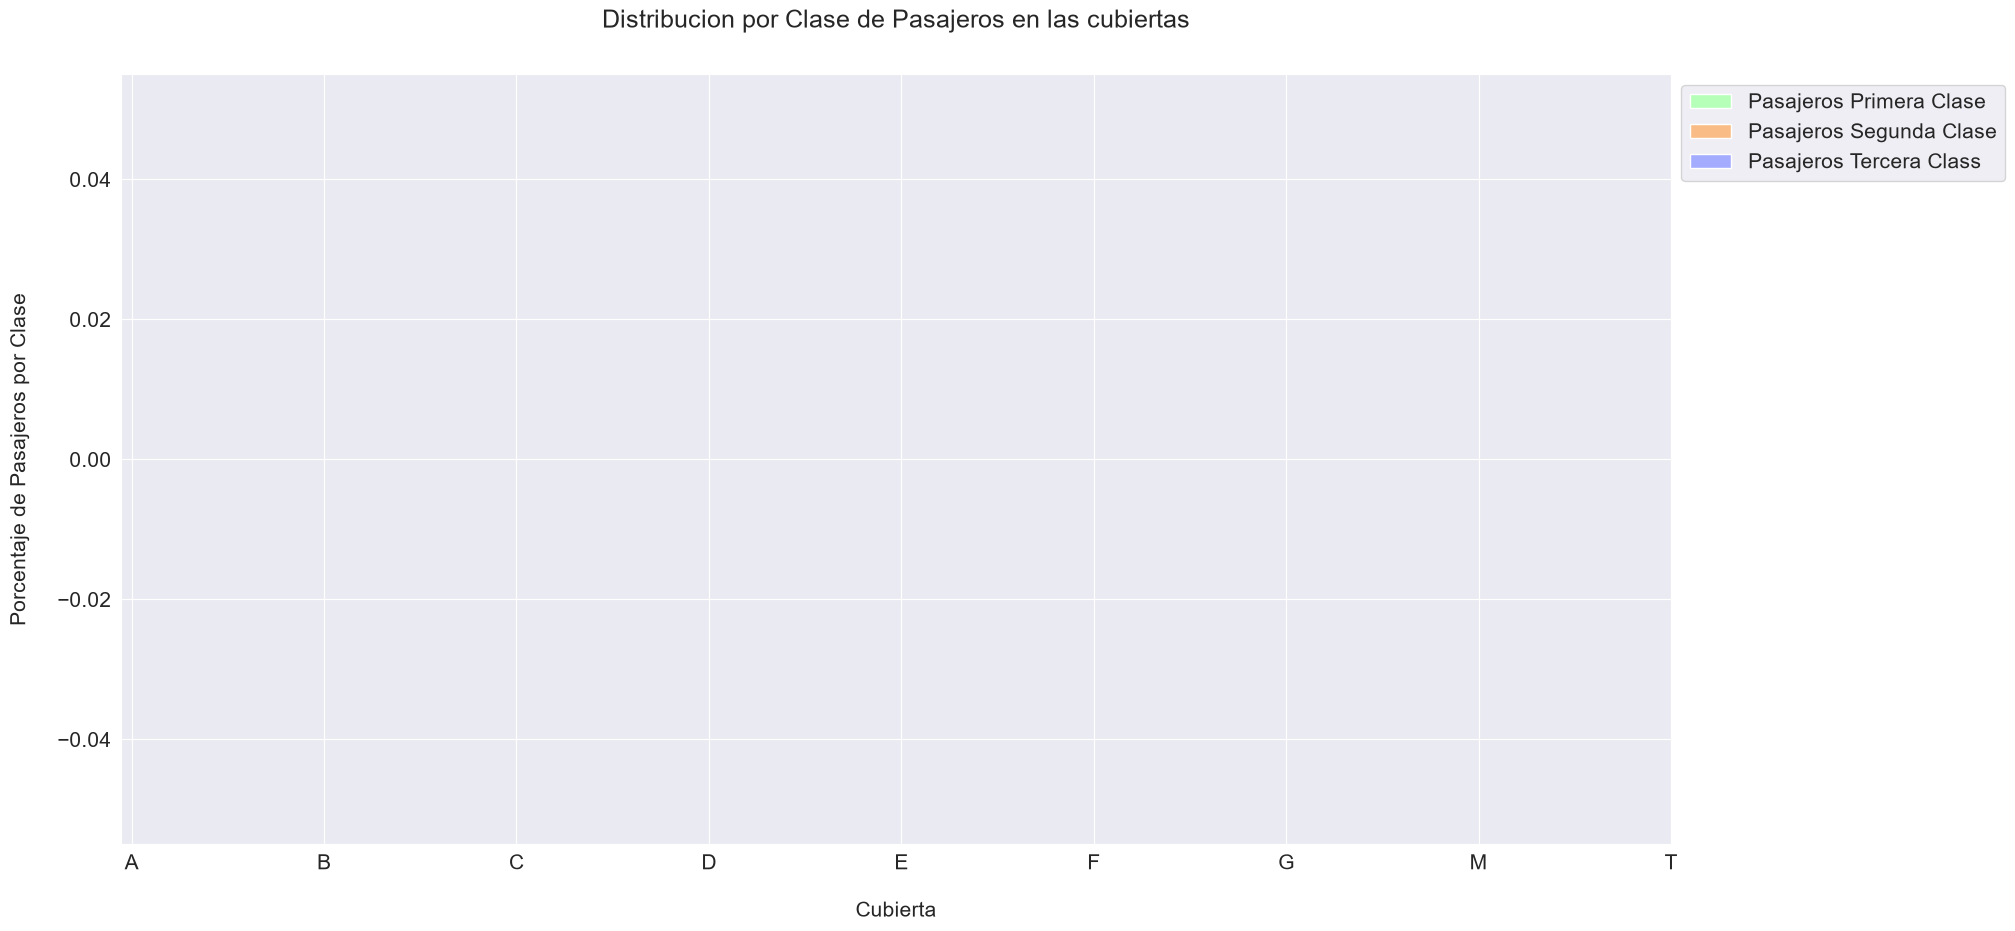

In [75]:
# Creamos el campo 'Cubierta/Deck'con la primera letra del campo 'Cabin' (M significa Missing)
df_all['Deck'] = df_all['Cabin'].apply(lambda s: s[0] if pd.notnull(s) else 'M')
df_all_decks = df_all.groupby(['Deck', 'Pclass']).count().drop(columns=['Survived', 'Sex', 'Age', 'SibSp', 'Parch',
                                                                        'Fare', 'Embarked', 'Cabin', 'PassengerId', 'Ticket']).rename(columns={'Name': 'Count'}).transpose()

def get_pclass_dist(df):

    # Creamos un diccionario para el total de pasajeros por clase en cada cubierta
    deck_counts = {'A': {}, 'B': {}, 'C': {}, 'D': {}, 'E': {}, 'F': {}, 'G': {}, 'M': {}, 'T': {}}
    decks = df.columns.levels[0]

    for deck in decks:
        for pclass in range(1, 4):
            try:
                count = df[deck][pclass][0]
                deck_counts[deck][pclass] = count
            except KeyError:
                deck_counts[deck][pclass] = 0

    df_decks = pd.DataFrame(deck_counts)
    deck_percentages = {}

    # Creamos un diccionario para el porcentaje de pasajeros por clase en cada cubierta
    for col in df_decks.columns:
        deck_percentages[col] = [(count / df_decks[col].sum()) * 100 for count in df_decks[col]]

    return deck_counts, deck_percentages

def display_pclass_dist(percentages):
    #print(percentages)
    df_percentages = pd.DataFrame(percentages).transpose()
    print(df_percentages)
    deck_names = ('A', 'B', 'C', 'D', 'E', 'F', 'G', 'M', 'T')
    bar_count = np.arange(len(deck_names))
    bar_width = 0.55

    pclass1 = df_percentages[0]
    pclass2 = df_percentages[1]
    pclass3 = df_percentages[2]

    plt.figure(figsize=(20, 10))
    plt.bar(bar_count, pclass1, color='#b5ffb9', edgecolor='white', width=bar_width, label='Pasajeros Primera Clase')
    plt.bar(bar_count, pclass2, bottom=pclass1, color='#f9bc86', edgecolor='white', width=bar_width, label='Pasajeros Segunda Clase')
    plt.bar(bar_count, pclass3, bottom=pclass1 + pclass2, color='#a3acff', edgecolor='white', width=bar_width, label='Pasajeros Tercera Class')

    plt.xlabel('Cubierta', size=15, labelpad=20)
    plt.ylabel('Porcentaje de Pasajeros por Clase', size=15, labelpad=20)
    plt.xticks(bar_count, deck_names)
    plt.tick_params(axis='x', labelsize=15)
    plt.tick_params(axis='y', labelsize=15)

    plt.legend(loc='upper left', bbox_to_anchor=(1, 1), prop={'size': 15})
    plt.title('Distribucion por Clase de Pasajeros en las cubiertas', size=18, y=1.05)

    plt.show()

all_deck_count, all_deck_per = get_pclass_dist(df_all_decks)

display_pclass_dist(all_deck_per)

In [76]:
# Pasajero en la cubierta T se cambia a A
idx = df_all[df_all['Deck'] == 'T'].index
df_all.loc[idx, 'Deck'] = 'A'

           0          1
A  56.250000  43.750000
B  25.531915  74.468085
C  40.677966  59.322034
D  24.242424  75.757576
E  25.000000  75.000000
F  38.461538  61.538462
G  50.000000  50.000000
M  70.014556  29.985444


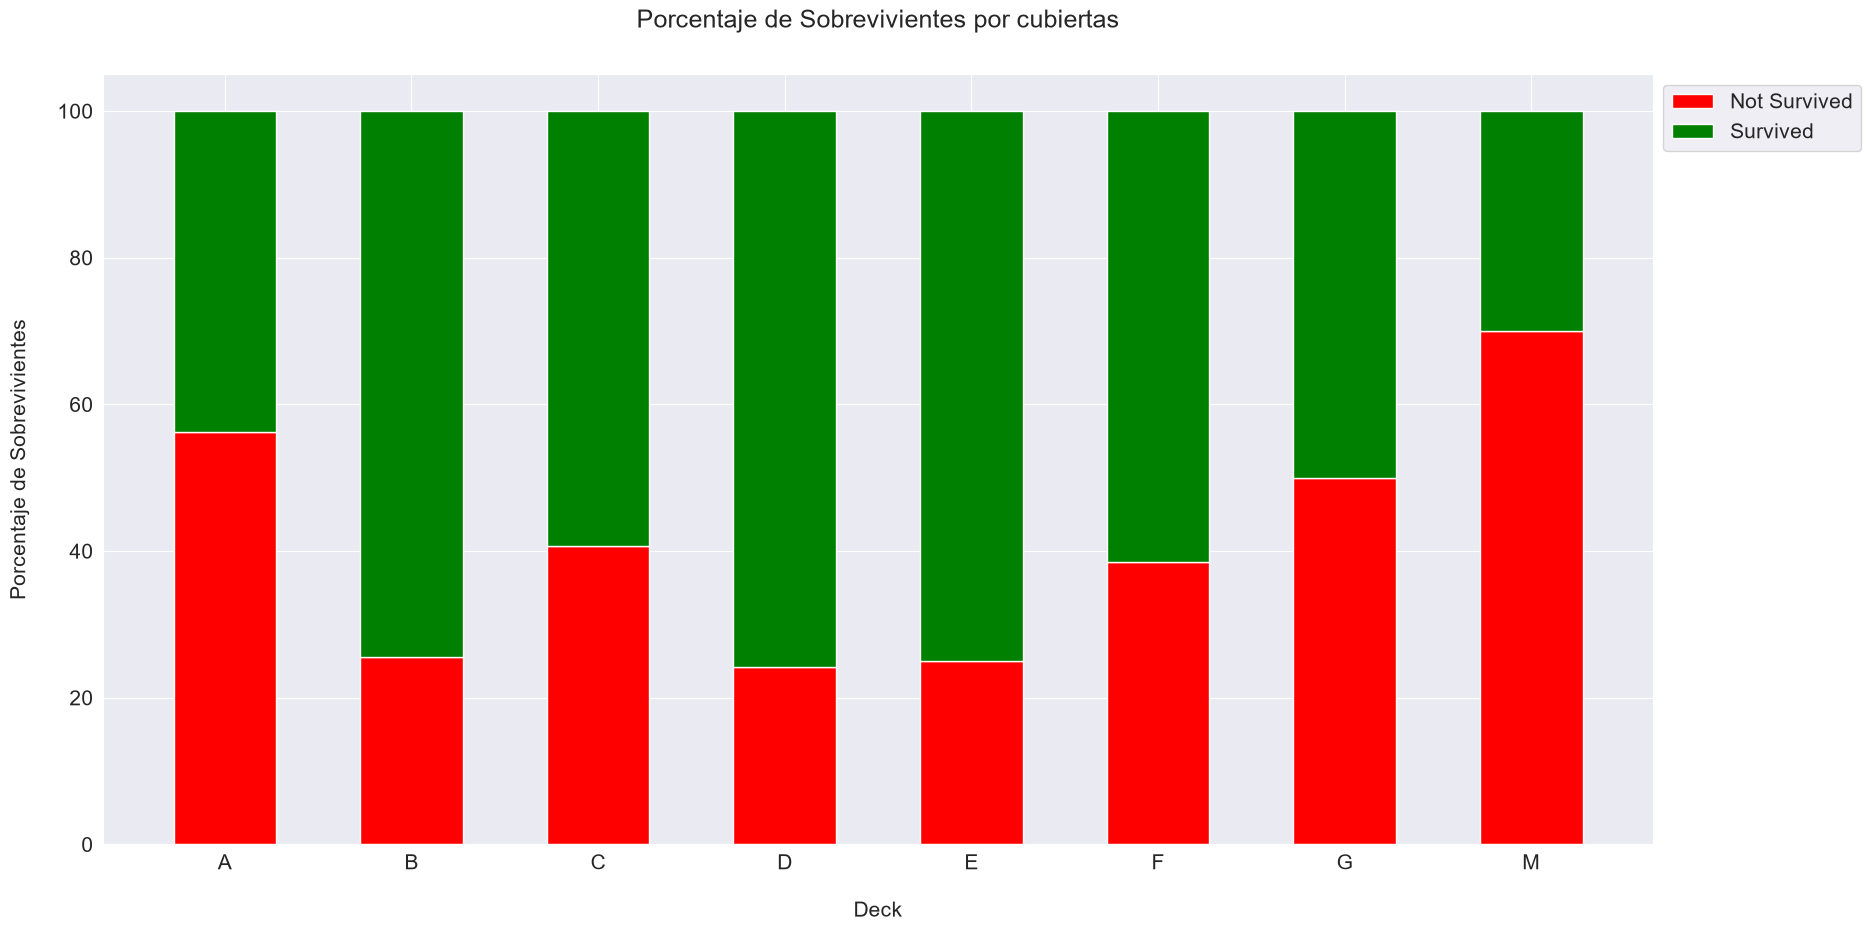

In [78]:
df_all_decks_survived = df_all.groupby(['Deck', 'Survived']).count().drop(columns=['Sex', 'Age', 'SibSp', 'Parch', 'Fare',
                                                                                   'Embarked', 'Pclass', 'Cabin', 'PassengerId', 'Ticket']).rename(columns={'Name':'Count'}).transpose()

def get_survived_dist(df):
    # Creamos un diccionario para cada sobreviviente contado en cada cubierta
    surv_counts = {'A':{0:0, 1:0}, 'B':{0:0, 1:0}, 'C':{0:0, 1:0}, 'D':{0:0, 1:0}, 'E':{0:0, 1:0}, 'F':{0:0, 1:0}, 'G':{0:0, 1:0}, 'M':{0:0, 1:0}}
    
    # Extraemos los datos de forma segura usando .get() para evitar los KeyErrors
    for col in df.columns:
        deck, survive = col
        if deck in surv_counts:
            surv_counts[deck][survive] = df.loc['Count', col]

    df_surv = pd.DataFrame(surv_counts)
    surv_percentages = {}

    for col in df_surv.columns:
        total = df_surv[col].sum()
        if total > 0:
            surv_percentages[col] = [(count / total) * 100 for count in df_surv[col]]
        else:
            surv_percentages[col] = [0.0, 0.0]

    return surv_counts, surv_percentages

def display_surv_dist(percentages):
    df_survived_percentages = pd.DataFrame(percentages).transpose()
    print(df_survived_percentages)
    deck_names = ('A', 'B', 'C', 'D', 'E', 'F', 'G', 'M')
    bar_count = np.arange(len(deck_names))
    bar_width = 0.55

    not_survived = df_survived_percentages[0]
    survived = df_survived_percentages[1]

    plt.figure(figsize=(20, 10))
    plt.bar(bar_count, not_survived, color='red', edgecolor='white', width=bar_width, label="Not Survived")
    plt.bar(bar_count, survived, bottom=not_survived, color='green', edgecolor='white', width=bar_width, label="Survived")

    plt.xlabel('Deck', size=15, labelpad=20)
    plt.ylabel('Porcentaje de Sobrevivientes', size=15, labelpad=20)
    plt.xticks(bar_count, deck_names)
    plt.tick_params(axis='x', labelsize=15)
    plt.tick_params(axis='y', labelsize=15)

    plt.legend(loc='upper left', bbox_to_anchor=(1, 1), prop={'size': 15})
    plt.title('Porcentaje de Sobrevivientes por cubiertas', size=18, y=1.05)

    plt.show()

all_surv_count, all_surv_per = get_survived_dist(df_all_decks_survived)
display_surv_dist(all_surv_per)

In [ ]:
df_all['Deck'] = df_all['Deck'].replace(['A', 'B', 'C'], 'ABC')
df_all['Deck'] = df_all['Deck'].replace(['D', 'E'], 'DE')
df_all['Deck'] = df_all['Deck'].replace(['F', 'G'], 'FG')

df_all['Deck'].value_counts()


In [ ]:
# Desechamos la variable cabina pues usamos la nueva variable Deck

df_all.drop(['Cabin'], inplace=True, axis=1)

df_train, df_test = divide_df(df_all)
dfs = [df_train, df_test]

for df in dfs:
    display_missing(df)

Distribucion de los Sobrevivientes (Target):

In [ ]:
survived = df_train['Survived'].value_counts()[1]
not_survived = df_train['Survived'].value_counts()[0]
survived_per = survived / df_train.shape[0] * 100
not_survived_per = not_survived / df_train.shape[0] * 100

print('{} de {} pasajeros sobrevivieron y eso es el {:.2f}% del conjunto de entrenamiento.'.format(survived, df_train.shape[0], survived_per))
print('{} de {} pasajeros no sobrevivieron y eso es el {:.2f}%  del conjunto de entrenamiento.'.format(not_survived, df_train.shape[0], not_survived_per))

plt.figure(figsize=(10, 8))
sns.countplot(x=df_train['Survived'])

plt.xlabel('Sobrevivieron', size=15, labelpad=15)
plt.ylabel('Numero de Pasajeros', size=15, labelpad=15)
plt.xticks((0, 1), ['No Sobrevivieron ({0:.2f}%)'.format(not_survived_per), 'Sobrevivieron ({0:.2f}%)'.format(survived_per)])
plt.tick_params(axis='x', labelsize=13)
plt.tick_params(axis='y', labelsize=13)

plt.title('Distribucion de Sobrevivientes en el Conjunto de Entrenamiento', size=15, y=1.05)

plt.show()

**Correlaciones:**

Las características están altamente correlacionadas entre sí y dependen unas de otras. La correlación más alta entre características es 0.549500 en el conjunto de entrenamiento y 0.577147 en el conjunto de prueba (entre Tarifa y Pclass). Las otras características también están altamente correlacionadas. Hay 9 correlaciones en el conjunto de entrenamiento y 6 correlaciones en el conjunto de prueba que son superiores a 0,1.

In [ ]:
df_train.shape

In [ ]:
df_train.hist(figsize=(15,13))
plt.show()

In [ ]:
df_train.plot(x="Fare", y="SibSp", kind="scatter", alpha=0.4)
plt.show()

In [ ]:
def process_correlation_matrix(df, drop_column=None):
    # Eliminar la columna específica si se proporciona
    if drop_column:
        df = df.drop([drop_column], axis=1)

    # Seleccionar solo las columnas numéricas
    df_numeric = df.select_dtypes(include=[float, int])

    # Calcular la matriz de correlación
    df_corr = df_numeric.corr(method='pearson').abs().unstack().sort_values(kind="quicksort", ascending=False).reset_index()

    # Renombrar las columnas resultantes
    df_corr.rename(columns={"level_0": "Feature 1", "level_1": "Feature 2", 0: 'Coeficiente Correlacion'}, inplace=True)

    # Eliminar duplicados donde Feature 1 es igual a Feature 2
    df_corr = df_corr[df_corr['Feature 1'] != df_corr['Feature 2']]

    # Eliminar duplicados inversos
    df_corr = df_corr.drop_duplicates(subset=['Coeficiente Correlacion'])

    return df_corr

In [ ]:
df_train_corr = process_correlation_matrix(df_train, drop_column='PassengerId')
df_train_corr_nd = df_train_corr[df_train_corr['Coeficiente Correlacion'] != 1.0]

# Procesar la matriz de correlación para df_test
df_test_corr = process_correlation_matrix(df_test)
df_test_corr_nd = df_test_corr[df_test_corr['Coeficiente Correlacion'] != 1.0]

# Mostrar los resultados
print("Matriz de Correlación de Entrenamiento (sin duplicados y correlaciones perfectas):")
print(df_train_corr_nd)

print("\nMatriz de Correlación de Prueba (sin duplicados y correlaciones perfectas):")
print(df_test_corr_nd)

In [ ]:
'''df_train_corr = df_train.drop(['PassengerId'], axis=1).corr(method='pearson').abs().unstack().sort_values(kind="quicksort", ascending=False).reset_index()
df_train_corr.rename(columns={"level_0": "Feature 1", "level_1": "Feature 2", 0: 'Coeficiente Correlacion'}, inplace=True)
df_train_corr.drop(df_train_corr.iloc[1::2].index, inplace=True)
df_train_corr_nd = df_train_corr.drop(df_train_corr[df_train_corr['Coeficiente Correlacion'] == 1.0].index)

df_test_corr = df_test.corr(method='pearson').abs().unstack().sort_values(kind="quicksort", ascending=False).reset_index()
df_test_corr.rename(columns={"level_0": "Feature 1", "level_1": "Feature 2", 0: 'Coeficiente Correlacion'}, inplace=True)
df_test_corr.drop(df_test_corr.iloc[1::2].index, inplace=True)
df_test_corr_nd = df_test_corr.drop(df_test_corr[df_test_corr['Coeficiente Correlacion'] == 1.0].index)'''

In [ ]:
# Conjunto de entrenamiento - correlaciones altas
corr = df_train_corr_nd['Coeficiente Correlacion'] > 0.1
df_train_corr_nd[corr]


In [ ]:
# Conjunto de prueba - correlaciones altas
corr = df_test_corr_nd['Coeficiente Correlacion'] > 0.4
df_test_corr_nd[corr]

In [ ]:
from pandas.plotting import scatter_matrix
attributes = ["Age","Pclass","Fare","Sex","Survived"]
scatter_matrix(df_train[attributes], figsize=(24,24))
plt.show()

In [ ]:
# Selecciona únicamente las columnas numéricas de df_train
df_train_numeric = df_train.drop(['PassengerId'], axis=1).select_dtypes(include=[float, int])

# Selecciona únicamente las columnas numéricas de df_test
df_test_numeric = df_test.select_dtypes(include=[float, int])

# Configuración del tamaño de la figura
fig, axs = plt.subplots(nrows=2, figsize=(20, 20))  # Tamaño ajustado para una mejor visualización

# Mapa de calor para el conjunto de entrenamiento
sns.heatmap(
    df_train_numeric.corr(),
    ax=axs[0],
    annot=True,
    square=True,
    cmap='coolwarm',
    annot_kws={'size': 10},  # Tamaño de la anotación ajustado
    cbar_kws={"shrink": .8}  # Tamaño de la barra de color ajustado
)

# Mapa de calor para el conjunto de prueba
sns.heatmap(
    df_test_numeric.corr(),
    ax=axs[1],
    annot=True,
    square=True,
    cmap='coolwarm',
    annot_kws={'size': 10},  # Tamaño de la anotación ajustado
    cbar_kws={"shrink": .8}  # Tamaño de la barra de color ajustado
)

# Ajustes de los ejes
for i in range(2):
    axs[i].tick_params(axis='x', labelsize=12)
    axs[i].tick_params(axis='y', labelsize=12)

# Títulos de los gráficos
axs[0].set_title('Correlaciones del Conjunto de Entrenamiento', size=16)
axs[1].set_title('Correlaciones del Conjunto de Prueba', size=16)

# Mostrar el gráfico
plt.show()

In [ ]:
'''fig, axs = plt.subplots(nrows=2, figsize=(40, 40))

sns.heatmap(df_train.drop(['PassengerId'], axis=1).corr(), ax=axs[0], annot=True, square=True, cmap='coolwarm', annot_kws={'size': 14})
sns.heatmap(df_test.drop(['PassengerId'], axis=1).corr(), ax=axs[1], annot=True, square=True, cmap='coolwarm', annot_kws={'size': 14})

for i in range(2):
    axs[i].tick_params(axis='x', labelsize=14)
    axs[i].tick_params(axis='y', labelsize=14)

axs[0].set_title('Correlaciones del Conjunto de Entrenamiento', size=15)
axs[1].set_title('Correlaciones del Conjunto de Prueba', size=15)

plt.show()'''

**DISTRIBUCION VARIABLE OBJETIVO POR FEATURES:**



CONTINUOS

In [ ]:
cont_features = ['Age', 'Fare']
surv = df_train['Survived'] == 1

fig, axs = plt.subplots(ncols=2, nrows=2, figsize=(20, 20))
plt.subplots_adjust(right=1.5)

for i, feature in enumerate(cont_features):
    # Distribution of survival in feature
    sns.histplot(df_train[~surv][feature], label='No Sobrevivio', kde=True, color='#e74c3c', ax=axs[0][i])
    sns.histplot(df_train[surv][feature], label='Sobrevivio', kde=True, color='#2ecc71', ax=axs[0][i])

    # Distribution of feature in dataset
    sns.histplot(df_train[feature], label='Conjunto de Entrenamiento', kde=False, color='#e74c3c', ax=axs[1][i])
    sns.histplot(df_test[feature], label='Conjunto de Prueba', kde=False, color='#2ecc71', ax=axs[1][i])

    axs[0][i].set_xlabel('')
    axs[1][i].set_xlabel('')

    for j in range(2):
        axs[i][j].tick_params(axis='x', labelsize=20)
        axs[i][j].tick_params(axis='y', labelsize=20)

    axs[0][i].legend(loc='upper right', prop={'size': 20})
    axs[1][i].legend(loc='upper right', prop={'size': 20})
    axs[0][i].set_title('Distribucion de sobrevivientes en {}'.format(feature), size=20, y=1.05)

axs[1][0].set_title('Distribucion de la variable {}'.format('Edad'), size=20, y=1.05)
axs[1][1].set_title('Distribucion de la variable {}'.format('Tarifa'), size=20, y=1.05)

plt.show()

CATEGORICOS

In [ ]:
cat_features = ['Embarked', 'Parch', 'Pclass', 'Sex', 'SibSp', 'Deck']

fig, axs = plt.subplots(ncols=2, nrows=3, figsize=(20, 20))
plt.subplots_adjust(right=1.5, top=1.25)
#print(df_train)
for i, feature in enumerate(cat_features, 1):
    plt.subplot(2, 3, i)
    sns.countplot(x=feature, hue='Survived', data=df_train)

    plt.xlabel('{}'.format(feature), size=20, labelpad=15)
    plt.ylabel('Cantidad de Pasajeros', size=20, labelpad=15)
    plt.tick_params(axis='x', labelsize=20)
    plt.tick_params(axis='y', labelsize=20)

    plt.legend(['No Sobrevivio', 'Sobrevivio'], loc='upper center', prop={'size': 18})
    plt.title('Cantidad de sobrevivientes por Variable {}'.format(feature), size=20, y=1.05)

plt.show()

In [ ]:
df_all = concat_df(df_train, df_test)
df_all.head()

**III FEATURE ENGINEERING**

En muchas actividades prácticas de ciencia de datos, el conjunto de datos contendrá variables categóricas. Estas variables normalmente se almacenan como valores de texto. Dado que el aprendizaje automático se basa en ecuaciones matemáticas, se generara un problema si mantenemos las variables categóricas como están. Muchos algoritmos admiten valores categóricos sin más manipulación, pero en esos casos, sigue siendo un tema de discusión sobre si codificar las variables o no. Los algoritmos que no soportan valores categóricos, en ese caso, utilizaran metodologías de codificación.

**Tarifa**

In [ ]:
df_all['Fare'] = pd.qcut(df_all['Fare'], 13)

In [ ]:
fig, axs = plt.subplots(figsize=(22, 9))
sns.countplot(x='Fare', hue='Survived', data=df_all)

plt.xlabel('Tarifa', size=15, labelpad=20)
plt.ylabel('Cantidad de Pasajeros', size=15, labelpad=20)
plt.tick_params(axis='x', labelsize=10)
plt.tick_params(axis='y', labelsize=15)

plt.legend(['No Sobrevivio', 'Sobrevivio'], loc='upper right', prop={'size': 15})
plt.title('Numero de sobrevivientes por variable {}'.format('Fare'), size=15, y=1.05)

plt.show()

**Age**

In [ ]:
df_all['Age'] = pd.qcut(df_all['Age'], 10)

In [ ]:
fig, axs = plt.subplots(figsize=(22, 9))
sns.countplot(x='Age', hue='Survived', data=df_all)

plt.xlabel('Edad', size=15, labelpad=20)
plt.ylabel('Cantidad de Pasajeros', size=15, labelpad=20)
plt.tick_params(axis='x', labelsize=15)
plt.tick_params(axis='y', labelsize=15)

plt.legend(['No Sobrevivio', 'Sobrevivio'], loc='upper right', prop={'size': 15})
plt.title('Cantidad de sobrevivientes por variable {}'.format('Age'), size=15, y=1.05)

plt.show()

**Frecuency Encoding**

In [ ]:
df_all['Family_Size'] = df_all['SibSp'] + df_all['Parch'] + 1

fig, axs = plt.subplots(figsize=(20, 20), ncols=2, nrows=2)
plt.subplots_adjust(right=1.5)

sns.barplot(x=df_all['Family_Size'].value_counts().index, y=df_all['Family_Size'].value_counts().values, ax=axs[0][0])
sns.countplot(x='Family_Size', hue='Survived', data=df_all, ax=axs[0][1])

axs[0][0].set_title('Cantidad variable tamaño de familia', size=20, y=1.05)
axs[0][1].set_title('Cantidad de sobrevivientes por tamaño de familia ', size=20, y=1.05)

family_map = {1: 'Alone', 2: 'Small', 3: 'Small', 4: 'Small', 5: 'Medium', 6: 'Medium', 7: 'Large', 8: 'Large', 11: 'Large'}
df_all['Family_Size_Grouped'] = df_all['Family_Size'].map(family_map)

sns.barplot(x=df_all['Family_Size_Grouped'].value_counts().index, y=df_all['Family_Size_Grouped'].value_counts().values, ax=axs[1][0])
sns.countplot(x='Family_Size_Grouped', hue='Survived', data=df_all, ax=axs[1][1])

axs[1][0].set_title('Cantidad variable tamaño de familia despues de agrupar', size=20, y=1.05)
axs[1][1].set_title('Cantidad de sobrevivientes por tamaño de familia  despues de  agrupar', size=20, y=1.05)

for i in range(2):
    axs[i][1].legend(['No Sobrevivio', 'Sobrevivio'], loc='upper right', prop={'size': 20})
    for j in range(2):
        axs[i][j].tick_params(axis='x', labelsize=20)
        axs[i][j].tick_params(axis='y', labelsize=20)
        axs[i][j].set_xlabel('')
        axs[i][j].set_ylabel('')

plt.show()

In [ ]:
df_all['Ticket_Frequency'] = df_all.groupby('Ticket')['Ticket'].transform('count')

In [ ]:
fig, axs = plt.subplots(figsize=(12, 9))
sns.countplot(x='Ticket_Frequency', hue='Survived', data=df_all)

plt.xlabel('Frecuencia del ticket', size=15, labelpad=20)
plt.ylabel('Cantidad de Pasajeros', size=15, labelpad=20)
plt.tick_params(axis='x', labelsize=15)
plt.tick_params(axis='y', labelsize=15)

plt.legend(['No Sobrevivio', 'Sobrevivio'], loc='upper right', prop={'size': 15})
plt.title('Numero de sobrevivientes segun variable {}'.format('Ticket Frequency'), size=15, y=1.05)

plt.show()

**Title & Is Married**

In [ ]:
df_all['Title'] = df_all['Name'].str.split(', ', expand=True)[1].str.split('.', expand=True)[0]
df_all['Is_Married'] = 0
df_all['Is_Married'].loc[df_all['Title'] == 'Mrs'] = 1

In [ ]:
fig, axs = plt.subplots(nrows=2, figsize=(20, 20))
sns.barplot(x=df_all['Title'].value_counts().index, y=df_all['Title'].value_counts().values, ax=axs[0])

axs[0].tick_params(axis='x', labelsize=10)
axs[1].tick_params(axis='x', labelsize=15)

for i in range(2):
    axs[i].tick_params(axis='y', labelsize=15)

axs[0].set_title('Cantidad Variable titulo', size=20, y=1.05)

df_all['Title'] = df_all['Title'].replace(['Miss', 'Mrs','Ms', 'Mlle', 'Lady', 'Mme', 'the Countess', 'Dona'], 'Miss/Mrs/Ms')
df_all['Title'] = df_all['Title'].replace(['Dr', 'Col', 'Major', 'Jonkheer', 'Capt', 'Sir', 'Don', 'Rev'], 'Dr/Military/Noble/Clergy')

sns.barplot(x=df_all['Title'].value_counts().index, y=df_all['Title'].value_counts().values, ax=axs[1])
axs[1].set_title('Cantidad Variable titulo despues de agrupar', size=20, y=1.05)

plt.show()

**Target Encoding**

In [ ]:
def extract_surname(data):

    families = []

    for i in range(len(data)):
        name = data.iloc[i]

        if '(' in name:
            name_no_bracket = name.split('(')[0]
        else:
            name_no_bracket = name

        family = name_no_bracket.split(',')[0]
        title = name_no_bracket.split(',')[1].strip().split(' ')[0]

        for c in string.punctuation:
            family = family.replace(c, '').strip()

        families.append(family)

    return families

df_all['Family'] = extract_surname(df_all['Name'])
df_train = df_all.loc[:890]
df_test = df_all.loc[891:]
dfs = [df_train, df_test]

In [ ]:
# Creando una lista de familias y tickets que ocurren tanto en el conjunto de entrenamiento como en el de prueba
non_unique_families = [x for x in df_train['Family'].unique() if x in df_test['Family'].unique()]
non_unique_tickets = [x for x in df_train['Ticket'].unique() if x in df_test['Ticket'].unique()]

# Agrupando por 'Family' y 'Ticket' y calculando la mediana
df_family_survival_rate = df_train.groupby('Family')[['Survived', 'Family_Size']].median()
df_ticket_survival_rate = df_train.groupby('Ticket')[['Survived', 'Ticket_Frequency']].median()

# Diccionarios para almacenar las tasas de supervivencia por familia y por ticket
family_rates = {}
ticket_rates = {}

# Iterando sobre las filas de df_family_survival_rate
for i in range(len(df_family_survival_rate)):
    family = df_family_survival_rate.index[i]
    family_size = df_family_survival_rate.iloc[i, 1]
    if family in non_unique_families and family_size > 1:
        family_rates[family] = df_family_survival_rate.iloc[i, 0]

# Iterando sobre las filas de df_ticket_survival_rate
for i in range(len(df_ticket_survival_rate)):
    ticket = df_ticket_survival_rate.index[i]
    ticket_frequency = df_ticket_survival_rate.iloc[i, 1]
    if ticket in non_unique_tickets and ticket_frequency > 1:
        ticket_rates[ticket] = df_ticket_survival_rate.iloc[i, 0]

# Mostrando los resultados
print("Family Survival Rates:", family_rates)
print("Ticket Survival Rates:", ticket_rates)


In [ ]:
# Creating a list of families and tickets that are occuring in both training and test set
'''non_unique_families = [x for x in df_train['Family'].unique() if x in df_test['Family'].unique()]
non_unique_tickets = [x for x in df_train['Ticket'].unique() if x in df_test['Ticket'].unique()]

df_family_survival_rate = df_train.groupby('Family')['Survived', 'Family','Family_Size'].median()
df_ticket_survival_rate = df_train.groupby('Ticket')['Survived', 'Ticket','Ticket_Frequency'].median()

family_rates = {}
ticket_rates = {}

for i in range(len(df_family_survival_rate)):
    # Checking a family exists in both training and test set, and has members more than 1
    if df_family_survival_rate.index[i] in non_unique_families and df_family_survival_rate.iloc[i, 1] > 1:
        family_rates[df_family_survival_rate.index[i]] = df_family_survival_rate.iloc[i, 0]

for i in range(len(df_ticket_survival_rate)):
    # Checking a ticket exists in both training and test set, and has members more than 1
    if df_ticket_survival_rate.index[i] in non_unique_tickets and df_ticket_survival_rate.iloc[i, 1] > 1:
        ticket_rates[df_ticket_survival_rate.index[i]] = df_ticket_survival_rate.iloc[i, 0]'''

In [ ]:
mean_survival_rate = np.mean(df_train['Survived'])

train_family_survival_rate = []
train_family_survival_rate_NA = []
test_family_survival_rate = []
test_family_survival_rate_NA = []

for i in range(len(df_train)):
    if df_train['Family'][i] in family_rates:
        train_family_survival_rate.append(family_rates[df_train['Family'][i]])
        train_family_survival_rate_NA.append(1)
    else:
        train_family_survival_rate.append(mean_survival_rate)
        train_family_survival_rate_NA.append(0)

for i in range(len(df_test)):
    if df_test['Family'].iloc[i] in family_rates:
        test_family_survival_rate.append(family_rates[df_test['Family'].iloc[i]])
        test_family_survival_rate_NA.append(1)
    else:
        test_family_survival_rate.append(mean_survival_rate)
        test_family_survival_rate_NA.append(0)

df_train['Family_Survival_Rate'] = train_family_survival_rate
df_train['Family_Survival_Rate_NA'] = train_family_survival_rate_NA
df_test['Family_Survival_Rate'] = test_family_survival_rate
df_test['Family_Survival_Rate_NA'] = test_family_survival_rate_NA

train_ticket_survival_rate = []
train_ticket_survival_rate_NA = []
test_ticket_survival_rate = []
test_ticket_survival_rate_NA = []

for i in range(len(df_train)):
    if df_train['Ticket'][i] in ticket_rates:
        train_ticket_survival_rate.append(ticket_rates[df_train['Ticket'][i]])
        train_ticket_survival_rate_NA.append(1)
    else:
        train_ticket_survival_rate.append(mean_survival_rate)
        train_ticket_survival_rate_NA.append(0)

for i in range(len(df_test)):
    if df_test['Ticket'].iloc[i] in ticket_rates:
        test_ticket_survival_rate.append(ticket_rates[df_test['Ticket'].iloc[i]])
        test_ticket_survival_rate_NA.append(1)
    else:
        test_ticket_survival_rate.append(mean_survival_rate)
        test_ticket_survival_rate_NA.append(0)

df_train['Ticket_Survival_Rate'] = train_ticket_survival_rate
df_train['Ticket_Survival_Rate_NA'] = train_ticket_survival_rate_NA
df_test['Ticket_Survival_Rate'] = test_ticket_survival_rate
df_test['Ticket_Survival_Rate_NA'] = test_ticket_survival_rate_NA

In [ ]:
for df in [df_train, df_test]:
    df['Survival_Rate'] = (df['Ticket_Survival_Rate'] + df['Family_Survival_Rate']) / 2
    df['Survival_Rate_NA'] = (df['Ticket_Survival_Rate_NA'] + df['Family_Survival_Rate_NA']) / 2

**Feature transformation**

Label Encoding Non-Numerical Features

In [ ]:
non_numeric_features = ['Embarked', 'Sex', 'Deck', 'Title', 'Family_Size_Grouped', 'Age', 'Fare']

for df in dfs:
    for feature in non_numeric_features:
        df[feature] = LabelEncoder().fit_transform(df[feature])

One-Hot Encoding the Categorical Features


In [ ]:
cat_features = ['Pclass', 'Sex', 'Deck', 'Embarked', 'Title', 'Family_Size_Grouped']
encoded_features = []

for df in dfs:
    for feature in cat_features:
        encoded_feat = OneHotEncoder().fit_transform(df[feature].values.reshape(-1, 1)).toarray()
        n = df[feature].nunique()
        cols = ['{}_{}'.format(feature, n) for n in range(1, n + 1)]
        encoded_df = pd.DataFrame(encoded_feat, columns=cols)
        encoded_df.index = df.index
        encoded_features.append(encoded_df)

df_train = pd.concat([df_train, *encoded_features[:6]], axis=1)
df_test = pd.concat([df_test, *encoded_features[6:]], axis=1)

In [ ]:
df_all = concat_df(df_train, df_test)
drop_cols = ['Deck', 'Embarked', 'Family', 'Family_Size', 'Family_Size_Grouped', 'Survived',
             'Name', 'Parch', 'PassengerId', 'Pclass', 'Sex', 'SibSp', 'Ticket', 'Title',
            'Ticket_Survival_Rate', 'Family_Survival_Rate', 'Ticket_Survival_Rate_NA', 'Family_Survival_Rate_NA']

df_all.drop(columns=drop_cols, inplace=True)

df_all.head()